# 面向设计复查的消费品召回危险分析

STAT 4073 数据挖掘课程项目 · 全量产品大类与家用设备子类对照

## 摘要

设计师决定先复查哪种危险时，产品类别应该分多细？参考其他产品的召回能否改善选择？本文用 RECALL-MM 的 6,874 条记录研究这两个问题。实验 A 用 Apriori 描述类别与危险的共现，按本类历史危险比例生成提示。实验 B 用 K-means 按失效构成给类别分组，将同簇其他类别的经验纳入排序。两者用 2000–2018 年公告建模，在 2019–2024 年公告上回测。

在能识别且历史样本达到建模条件的家电子类中，两种粒度共用 241 起建模召回、73 起回测召回和每起两项提示。使用具体子类找回了大类遗漏的 13 起，同时漏掉原先命中的 1 起，命中由 45 起增至 57 起。在 11 个产品大类中，同簇类别的历史危险构成平均更接近；但同簇经验占 50% 时，六个候选阈值下 B 的整体命中数和 micro-F1 均低于 A。固定两项时，A、B 的 micro-F1 分别为 0.435 和 0.382。补充分析 D 以 A 的前两项危险和设计师提供的结构检索全期公告。折叠或铰链与跌落的占比差在交通运输全类为 +65.9 个百分点，限于自行车相关名称后为 +25.2 个百分点。设计师可据此选择参照范围，再用匹配公告记载的失效过程确定复查部位。

**关键词**　消费品召回、关联规则、聚类、危险提示、设计复查

## 1 引言

在产品设计复查阶段，设计人员可以查阅相同或相似产品的历史事故记录。产品的失效方式描述发生了什么，例如部件断裂。危险标签描述可能产生的后果，例如跌落或撞击伤害。具有相似失效方式的大类能否共享危险经验，需要通过回测期召回验证。本文先测量本类历史能覆盖多少回测期危险，再检验加入同簇经验后，新增和遗漏的危险能否带来整体改善。

### 1.1 相关工作与本研究的问题

RECALL-MM 基于美国消费品安全委员会的召回资料构建。原研究用 Sentence-BERT 表示产品名称和召回描述，再用 t-SNE 展示文本相似的案例，为设计师提供探索历史公告的入口。本文沿用其公告与危险标签，进一步检验一个可回测的问题：知道某个产品属于哪一类时，借用其他类别的经验，能否让有限的提示覆盖更多后来公告中的危险？[RECALL-MM，第 3.2 节](https://arxiv.org/html/2503.23213v1#S3.SS2)

Apriori 的逐层候选筛选[2]适合列出有多少召回同时标注了某类产品和某种危险。K-means++ 初始化[3]和轮廓系数[4]用于建立和检查产品大类的分组。分组质量与危险提示效果分别评价，从而可以检验失效构成相近的类别能否共享危险排序。

本文先用数据集统一提供的大类标签覆盖全部记录，比较 A 和 B 的总体表现。再以家用设备做子类对照，检验在已知空调及热泵、取暖器或锅炉等具体产品类型时，细分历史能否改善提示。原始产品名称没有覆盖全库的统一子类标签，家用设备的子类由既有名称词典提取。

本 Notebook 报告 A、B 及补充分析 D，沿用小组项目编号。A 检验已知产品类别能否提供危险提示，B 检验引入同簇经验能否改善提示，D 接收 A 的固定前两项提示，在相同产品类别内比较提到结构与未提到结构的公告，再回查失效部位。

**时间划分只用于 A、B 的回测。** 可以把这两项实验想成在 2018 年底做设计评审。用截至当年的公告确定危险提示，再用 2019–2024 年发布的公告检验提示。D 从今天回看 2000–2024 年的全部公告，为设计师寻找可复查的案例。D 的规则和案例不参与 A、B 的建模、阈值选择或计分。

## 2 数据范围与预处理

### 2.1 读取召回公告

本 Notebook 通过共享数据接口读取原始 RECALL-MM 来源行，复现早期实验的「旧编号 × 大类」口径。可将原始 JSON 放在仓库根目录，或在下方设置 `DATA_PATH`，然后从头运行所有单元。环境需要 Jupyter、NumPy、SciPy、scikit-learn、threadpoolctl 和 Matplotlib。重绘中文图时需要可用的中文字体。

数据来源为 [RECALL-MM 项目仓库](https://github.com/dianabolanos/RECALL-MM)。下载 [原始 dataset.json](https://raw.githubusercontent.com/dianabolanos/RECALL-MM/main/dataset.json) 后放到 Notebook 同一目录即可复算。已核对公开文件与本文使用的 6,874 条 JSON 记录一致。

In [1]:
from collections import Counter, defaultdict
from fractions import Fraction
from io import BytesIO
from itertools import combinations
import sys
from pathlib import Path
import re
from statistics import mean

import numpy as np
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
from threadpoolctl import threadpool_limits

project_dir = next((
    base for base in (Path.cwd(), Path.cwd().parent, Path.cwd() / "DM-project")
    if (base / "recall_audit/scripts/project_data.py").is_file()
), None)
if project_dir is None:
    raise FileNotFoundError("Start the notebook from the project, recall_audit, or their parent directory.")
sys.path.insert(0, str(project_dir / "recall_audit/scripts"))
from project_data import load_source

DATA_PATH = None  # Set explicitly to use a copy of the original dataset elsewhere.
raw = load_source(DATA_PATH).records
assert len(raw) == 6874
print(f"原始记录：{len(raw):,} 条，{len({row['recall_number'] for row in raw}):,} 个召回编号")

from html import escape
from IPython.display import HTML, Image, display

def show_table(title, columns, rows):
    header = "".join(f'<th scope="col">{escape(str(x))}</th>' for x in columns)
    body = "".join("<tr>" + "".join(f"<td>{escape(str(x))}</td>" for x in row) + "</tr>" for row in rows)
    display(HTML(f'<table><caption style="caption-side:top;text-align:left;color:#28578d;font-weight:bold">{escape(title)}</caption>'
                 f'<thead style="background:#dfebf7"><tr>{header}</tr></thead><tbody>{body}</tbody></table>'))

原始记录：6,874 条，6,464 个召回编号


### 2.2 去重、识别失效方式与划分年份

按「召回编号 × 产品大类」合并重复记录。同一组合中的相同危险标签或相同失效方式只计一次。42 个召回编号跨越多个大类，这些召回保留各大类对应的原始危险标签。时间划分按召回编号进行，同一编号不会同时进入建模期和回测期。11 个大类全部满足建模期至少 10 起召回、其中至少 5 起识别到失效方式的条件。

使用原实验的六类英文关键词从公告描述中识别失效方式。建模期的识别覆盖率为 52.9%，回测期为 48.3%。没有匹配到关键词的召回仍用于危险频率和最终计分。

In [2]:
MODES = {
    '过热': r'overheat(?:s|ed|ing)?',
    '电气短路或电弧': r'short[- ]circuit(?:s|ed|ing)?|(?:electrical|electric) shorts?|arc(?:ing|s)',
    '破裂或断裂': r'break(?:s|ing)?|broken|crack(?:s|ed|ing)?|shatter(?:s|ed|ing)?|fracture(?:s|d)?',
    '松脱或分离': r'detach(?:es|ed|ing)?|separat(?:e|es|ed|ing)|(?:come|comes|become|becomes) loose|loosen(?:s|ed|ing)?|fall off',
    '泄漏': r'leak(?:s|ed|ing|age)?',
    '意外启动': r'(?:turn on|activate|start) (?:unexpectedly|unintentionally|by itself)|(?:unintentionally|unexpectedly) (?:turn on|activate|start)',
}


MODES['过热'] += r'|(?:get|gets|become) too hot|temperatures? (?:exceeds? allowable|can get too high)|elevated internal temperature|temperature of the storage drawer can become extremely high|heat to build up'


MODES['电气短路或电弧'] += r'|(?:electric|electrical) arc|short(?:s|ed)? out'


MODES['破裂或断裂'] += r'|ruptur(?:e|es|ed)|burst(?:s)?'


MODES['松脱或分离'] += r'|pulled loose|dislodg(?:e|es|ed)|detachments?|disengage|fall from (?:its housing|the ceiling|the wall)'


MODES['泄漏'] += r'|(?:flue gas|gas) (?:can|to) escape|gas to be released'


MODES['意外启动'] += r'|turn on (?:by themselves|without user input|spontaneously)|activated by accidental contact'

def matches(dictionary, phrase):
    return [name for name, pattern in dictionary.items()
            if re.search(r'\b(?:' + pattern + r')\b', phrase, re.I)]


CATEGORY_NAMES = {
    "HOME_APPLIANCES": "家用设备", "TOYS_CHILDREN": "玩具及儿童用品",
    "TRANSPORTATION": "交通运输", "SPORTS_RECREATION": "运动休闲",
    "ELECTRICAL": "电气产品", "CLOTHING_ACCESSORIES": "服装及配饰",
    "FURNITURE": "家具", "BABY_PRODUCTS": "婴幼儿用品", "OTHER": "其他产品",
    "TOOLS_HARDWARE": "工具及五金", "OUTDOOR_EQUIPMENT": "户外设备",
}


HAZARD_NAMES = {
    "FIRE": "火灾", "FALLING": "跌落", "CHOKING": "窒息或噎塞", "POISONING": "中毒",
    "BURN": "灼伤", "IMPACT": "撞击伤害", "CUTS": "割伤", "CRASH": "碰撞事故",
    "OTHER": "其他危险", "SAFETY_EQUIPMENT_MALFUNCTION": "安全装备失灵",
    "HEAT_RELATED_EXPOLOSION": "热相关爆炸",
}


def prepare(raw):
    """Keep each ID–category pair and merge only its corresponding raw labels."""
    cases = {}
    years = {}
    for row in raw:
        rid = row["recall_number"]
        year = int(row["recall_date"][:4])
        if years.setdefault(rid, year) != year:
            raise ValueError(f"Conflicting years for recall {rid}")
        if not row["product_classification"] or not row["hazard_classification"]:
            raise ValueError(f"Unlabeled row for recall {rid}")
        modes = matches(MODES, row["recall_description"])
        for category in row["product_classification"]:
            pair = (rid, category)
            case = cases.setdefault(pair, {
                "id": rid, "year": year, "subtype": category, "hazards": set(), "modes": set(),
                "raw_entries": [],
            })
            case["hazards"].update(row["hazard_classification"])
            case["modes"].update(modes)
            case["raw_entries"].append({
                "product": row["product_name"], "description": row["recall_description"],
                "hazards": row["hazard_classification"],
            })
    assert sum(len(case["raw_entries"]) for case in cases.values()) == len(raw)
    return list(cases.values())


def partition(cases):
    groups = defaultdict(list)
    for case in cases:
        groups[case["subtype"]].append(case)
    return groups


def unique_count(cases):
    return len({case["id"] for case in cases})


def hazards_per_recall(cases):
    result = defaultdict(set)
    for case in cases:
        result[case["id"]].update(case["hazards"])
    return result

def eligible_families(groups):
    return [t for t, events in groups.items()
            if len(events) >= 10 and sum(bool(r["modes"]) for r in events) >= 5]

cases = prepare(raw)
early = [c for c in cases if c["year"] <= 2018]
late = [c for c in cases if c["year"] > 2018]
assert {c["id"] for c in early}.isdisjoint(c["id"] for c in late)
assert unique_count(early) + unique_count(late) == unique_count(cases)
groups = partition(early)
late_groups = partition(late)
categories = sorted(groups)
assert set(categories) == set(CATEGORY_NAMES) == set(late_groups) == set(eligible_families(groups))
labels = sorted({h for c in early for h in c["hazards"]})
assert set(labels) == set(HAZARD_NAMES) == {h for c in late for h in c["hazards"]}

In [3]:
show_table('表 1  全量数据及时间划分', ['范围', '召回编号', '编号 × 大类', '识别到失效的组合'],
           [(name, f"{unique_count(records):,}", f"{len(records):,}", f"{sum(bool(r['modes']) for r in records):,}")
            for name, records in (("全部 2000–2024 年", cases), ("建模期 2000–2018 年", early), ("回测期 2019–2024 年", late))])

范围,召回编号,编号 × 大类,识别到失效的组合
全部 2000–2024 年,"6,464","6,507","3,373"
建模期 2000–2018 年,"4,978","5,016","2,653"
回测期 2019–2024 年,"1,486","1,491",720


## 3 危险提示、阈值选择与评价

- **历史建模期（2000–2018 年）** 用这段历史建立 A 的规则与危险频率，构造 B 的失效特征并确定分簇。全量共有 5,016 个召回编号与大类组合。
- **回测期（2019–2024 年）** 用已定好的方法给 1,491 个组合生成提示，并与这些公告的危险标签对照计分。
- **全期案例分析（2000–2024 年）** D 使用 A 的固定前两项作为查询条件，利用全期有外观文字的召回估计同类占比差并检索案例。

### 3.1 怎样生成并评价一份提示清单

A、B 都要回答同一个问题：给定产品类别，应提示哪些危险？两者都从同一套危险标签中选择，也都用回测公告原有的 `hazard_classification` 评价。A 的得分是本类历史危险比例，B 的得分是本类比例与同簇平均比例的等权组合。得分达到阈值的危险全部纳入，如果少于两项，就按分数取前两项。得分并列时，依次按建模期全局频数和标签名称排序。阈值决定要提示多少种危险。关联规则表至少 5 起共现的展示门槛用于筛选正文中的历史规则。

全局基线向所有大类输出相同的总体高频危险。

最小计分单位为「召回编号 × 产品大类 × 危险标签」。将实际标签与模型提示交叉匹配，累计正确提示 TP、公告未标注的提示 FP 和遗漏标签 FN，按 2TP / (2TP + FP + FN) 计算 micro-F1。另报告至少命中一个标签的记录数、按大类命中率以及各危险标签的召回率。固定每个组合提示两项，检验主要结果是否受提示数量影响。

In [4]:
def hazard_rates(events, hazards):
    return {h: Fraction(sum(h in r["hazards"] for r in events), len(events)) for h in hazards}


def ranked_hazards(scores, global_count):
    return sorted(scores, key=lambda h: (-scores[h], -global_count[h], h))


def top_k(scores, global_count, k):
    return ranked_hazards(scores, global_count)[:k]


def choose(scores, global_count, threshold):
    order = ranked_hazards(scores, global_count)
    above = [h for h in order if scores[h] >= threshold]
    return (above if len(above) >= 2 else order[:2]), above


def measure(test, predictions, labels):
    counts = {h: Counter() for h in labels}
    matched = prompts = extras = 0
    for r in test:
        pred = set(predictions[r["subtype"]])
        actual = r["hazards"]
        matched += bool(pred & actual)
        prompts += len(pred)
        extras += len(pred) > 2
        for h in labels:
            counts[h]["tp" if h in pred and h in actual else
                      "fp" if h in pred else "fn" if h in actual else "tn"] += 1
    totals = sum(counts.values(), Counter())

    def rates(c):
        tp, fp, fn = (c[k] for k in ("tp", "fp", "fn"))
        return {
            **{key:c[key] for key in ("tp","fp","fn","tn")}, "n_ref": tp+fn,
            "precision": tp/(tp+fp) if tp+fp else None,
            "recall": tp/(tp+fn) if tp+fn else None,
            "f1": 2*tp/(2*tp+fp+fn) if 2*tp+fp+fn else None,
        }

    return {
        **rates(totals), "n": len(test), "hit": matched, "hit_rate": matched/len(test),
        "prompts": prompts, "average_prompts": prompts/len(test), "extra_events": extras,
        "metrics_by_hazard": {h: rates(c) for h, c in counts.items()},
    }

### 3.2 在建模期内选择阈值

选阈值在历史建模期内部进行。先用 2000–2013 年的公告估计 A 的危险比例，再用 2014–2018 年的 1,263 个组合比较阈值。先选 micro-F1 较高的方案，并列时优先选择提示更少的方案，仍并列则取较低的阈值。选定后使用完整的 2000–2018 年数据重新建模，再对 2019–2024 年回测。

In [5]:
def threshold_curve(early, labels):
    training = [case for case in early if case["year"] <= 2013]
    training_groups = partition(training)
    validation = [case for case in early if case["year"] >= 2014]
    prior = Counter(h for hazards in hazards_per_recall(training).values() for h in hazards)
    scores = {t: hazard_rates(cases, labels) for t, cases in training_groups.items()}
    curve = []
    for value in range(10, 36, 5):
        threshold = Fraction(value, 100)
        predictions = {t: choose(score, prior, threshold)[0] for t, score in scores.items()}
        metrics = measure(validation, predictions, labels)
        curve.append({"threshold": float(threshold), **{
            key: metrics[key] for key in ("n", "f1", "precision", "recall", "average_prompts")
        }})
    return curve

curve = threshold_curve(early, labels)
selected = max(curve, key=lambda r: (r["f1"], -r["average_prompts"], -r["threshold"]))
THRESHOLD = Fraction(str(selected["threshold"]))
assert THRESHOLD == Fraction(15, 100)

show_table('表 2  阈值备选方案的比较（2014–2018 年）', ['候选阈值', '平均提示数', '精确率', '召回率', 'micro-F1'],
           [(f"{r['threshold']:.2f}", f"{r['average_prompts']:.2f}", f"{r['precision']:.1%}",
             f"{r['recall']:.1%}", f"{r['f1']:.3f}") for r in curve])

候选阈值,平均提示数,精确率,召回率,micro-F1
0.10,2.61,28.8%,73.5%,0.414
0.15,2.00,32.7%,64.2%,0.434
0.20,2.00,32.7%,64.2%,0.434
0.25,2.00,32.7%,64.2%,0.434
0.30,2.00,32.7%,64.2%,0.434
0.35,2.00,32.7%,64.2%,0.434


在 2014–2018 年验证集上，0.10 的平均提示数更多，micro-F1 较低。0.15、0.20、0.25、0.30、0.35 五档的平均提示数均为 2.00。由于每类至少取前两项，五档均输出相同的前两项清单，micro-F1 均为 0.434。按预设的并列规则选取 0.15。验证集能支持这组候选，但仅凭它无法判断哪个阈值最适合增加第三项。用截至 2018 年的资料重新拟合后，得分会变化。第 6 节用全部六档复核结论对阈值的敏感性，主方案始终使用 0.15。

## 4 实验 A 本类关联及危险提示

### 4.1 单条规则及低频危险

Apriori 先计数单项，再生成并筛选二项候选[2]。产品大类和危险标签须在同类原始记录中共现，规则以独立召回编号去重。规则支持度等于共现次数除以建模期全部召回编号数。置信度等于共现次数除以本类建模期召回数。提升度等于置信度除以该危险的总体建模期频率。本文逐条用直接计数核验 Apriori 的结果。正文用至少 5 次共现筛选显示规则，预测得分使用全部本类建模期危险比例。另计算全期关联规则，用于描述全部数据的历史构成。

一条规则写成「产品大类 → 一个危险标签」。同一个大类可以生成多条规则，各自计算建模期置信度和提升度。表 3 列出五条达到常规门槛的规则，末行另列一条低频对照，展示按共现次数筛选时会漏掉什么。

In [6]:
DISPLAY_MIN = 5


def apriori(rows, min_support):
    """Compute frequent 1- and 2-itemsets, with event-level support."""
    baskets = [
        (r["id"], frozenset([("family", r["subtype"]), *(("hazard", h) for h in r["hazards"])]))
        for r in rows
    ]
    item_events = {
        item: {i for i, basket in baskets if item in basket}
        for item in sorted(set().union(*(basket for _, basket in baskets)))
    }
    singles = [item for item, ids in item_events.items() if len(ids) >= min_support]
    pairs = {}
    for x, y in combinations(singles, 2):
        pair_ids = {i for i, basket in baskets if x in basket and y in basket}
        if len(pair_ids) >= min_support:
            pairs[x, y] = pair_ids
    rules = {}
    for pair, ids in pairs.items():
        items = dict(pair)
        if items.keys() == {"family", "hazard"}:
            rules[items["family"], items["hazard"]] = len(ids)
    return rules, {"singles": len(singles), "pairs_tested": len(singles)*(len(singles)-1)//2,
                   "frequent_pairs": len(pairs)}

def association(cases):
    groups = partition(cases)
    # Category and label evidence is attached to its original recall ID. The
    # denominator and background frequency are across unique recall IDs.
    population = unique_count(cases)
    label_ids = defaultdict(set)
    for case in cases:
        for hazard in case["hazards"]:
            label_ids[hazard].add(case["id"])
    direct = Counter((case["subtype"], h) for case in cases for h in case["hazards"])
    rules, stages = apriori(cases, 1)
    displayed, _ = apriori(cases, DISPLAY_MIN)
    assert rules == direct
    assert displayed == {key: n for key, n in direct.items() if n >= DISPLAY_MIN}
    modeled = [{
        "category": t, "hazard": h, "count": n, "category_count": len(groups[t]),
        "support": n / population, "confidence": n / len(groups[t]),
        "lift": n * population / (len(groups[t]) * len(label_ids[h])),
        "display": n >= DISPLAY_MIN,
    } for (t, h), n in sorted(rules.items())]
    return modeled, direct, stages

rules, direct, rule_stages = association(early)
full_rules, _, _ = association(cases)
peaks = Counter()
for case in late:
    for h in case["hazards"]:
        count = direct[case["subtype"], h]
        peaks["displayed" if count >= DISPLAY_MIN else "low" if count else "unseen"] += 1

early_rules, all_period_rules = rules, full_rules
rule_index = {(r["category"], r["hazard"]): r for r in rules}
examples = [("HOME_APPLIANCES", "FIRE"), ("FURNITURE", "FALLING"), ("TRANSPORTATION", "CRASH"),
            ("TOOLS_HARDWARE", "CUTS"), ('TOYS_CHILDREN', "CHOKING"), ("BABY_PRODUCTS", "BURN")]
rule_rows = []
for category, hazard in examples:
    r = rule_index[category, hazard]
    name = f"{CATEGORY_NAMES[category]} → {HAZARD_NAMES[hazard]}"
    if not r["display"]:
        name += "（低频对照）"
    rule_rows.append((name, f"{r['count']}/{r['category_count']}",
                      f"{r['confidence']:.1%}", f"{r['lift']:.2f}"))

show_table('表 3  代表性建模期关联规则', ['产品大类与危险', '共现数 / 本类总数', '置信度', '提升度'],
           rule_rows)

print("建模期规则数", len(rules), "达到展示门槛", sum(r["display"] for r in rules), "全期规则数", len(full_rules))
print("回测期标签按建模期共现数分组（≥5 次、1–4 次、0 次）", peaks["displayed"], peaks["low"], peaks["unseen"])
assert (len(rules), sum(r["display"] for r in rules), len(full_rules)) == (108, 93, 109)

产品大类与危险,共现数 / 本类总数,置信度,提升度
家用设备 → 火灾,507/918,55.2%,2.15
家具 → 跌落,185/304,60.9%,3.77
交通运输 → 碰撞事故,230/490,46.9%,8.62
工具及五金 → 割伤,97/268,36.2%,5.06
玩具及儿童用品 → 窒息或噎塞,409/938,43.6%,2.77
婴幼儿用品 → 灼伤（低频对照）,4/312,1.3%,0.17


建模期规则数 108 达到展示门槛 93 全期规则数 109
回测期标签按建模期共现数分组（≥5 次、1–4 次、0 次） 1477 18 1


建模期共有 108 条有观测支持的规则，其中 93 条达到 5 次共现。全期描述性分析共得到 109 条规则。交通运输的碰撞事故相对总体出现得更集中，提升度为 8.62。家用设备的火灾置信度为 55.2%，相对总体的提升度为 2.15。两项指标分别说明本类标签的覆盖比例及其相对总体的集中程度。

在 1,496 个回测期危险标签中，1,477 个对应建模期至少 5 次的组合，18 个对应只出现过 1 至 4 次的组合，另有 1 次标签观测在建模期没有对应的类别与危险组合。例如婴幼儿用品与灼伤，建模期共现 4 次，低于展示门槛，回测期仍出现 4 次。在同一 0.15 阈值与最少两项的规则下，全局基线命中 710 条记录，A 命中 1,049 条，说明产品大类包含可用于提示的历史信息。

### 4.2 各产品大类的最终危险提示

实验 A 用本类每条规则的置信度给危险排序，并按第 3 节的阈值与补足规则生成清单。表 4 列出 11 个大类的全部实际提示，括号内为建模期危险比例，星号标记低于 0.15 后按排名补入的危险。

In [7]:
rates = {t: hazard_rates(groups[t], labels) for t in categories}

hazards_by_id = hazards_per_recall(early)
prior = Counter(h for values in hazards_by_id.values() for h in values)
global_rates = {h: Fraction(prior[h], len(hazards_by_id)) for h in labels}

alerts_a = {t: choose(rates[t], prior, THRESHOLD)[0] for t in categories}
alert_rows = []
for t in sorted(categories, key=lambda t: -len(groups[t])):
    prompts = [f"{HAZARD_NAMES[h]}（{float(rates[t][h]):.1%}）" + ("*" if rates[t][h] < THRESHOLD else "")
               for h in alerts_a[t]]
    alert_rows.append([CATEGORY_NAMES[t], *prompts]) 
width = max(len(row) for row in alert_rows)
show_table("表 4  实验 A 对全部产品大类的危险提示清单",
           ["产品大类"] + [f"第 {i} 项" for i in range(1, width)],
           [row + ["—"] * (width - len(row)) for row in alert_rows])

产品大类,第 1 项,第 2 项,第 3 项
玩具及儿童用品,窒息或噎塞（43.6%）,中毒（25.9%）,—
家用设备,火灾（55.2%）,灼伤（14.5%）*,—
交通运输,碰撞事故（46.9%）,跌落（27.6%）,火灾（17.8%）
运动休闲,跌落（40.0%）,撞击伤害（25.0%）,—
电气产品,火灾（61.5%）,灼伤（13.5%）*,—
服装及配饰,窒息或噎塞（52.8%）,灼伤（18.5%）,—
婴幼儿用品,窒息或噎塞（45.5%）,跌落（36.9%）,—
家具,跌落（60.9%）,火灾（9.9%）*,—
工具及五金,割伤（36.2%）,火灾（20.9%）,撞击伤害（17.5%）
户外设备,火灾（51.1%）,跌落（12.4%）*,—


家用设备的火灾得分为 55.2%，灼伤为 14.5%。只有火灾达标，因此补入得分第二的灼伤。交通运输的碰撞事故、跌落和火灾均达到阈值，因此三项全部保留。

### 4.3 产品子类构成怎样影响大类清单？

交通运输的三项提示来自不同类型产品汇总后的危险比例。这里比较两组产品名称，分别检查哪组公告贡献了较多的火灾和跌落标签，以及移除这组公告后清单怎样变化。

沿用 A 的 490 起交通运输类建模召回。按召回编号检查该类原始产品名称。自行车组沿用第 8.4 节的独立词 `bicycle` 或 `bicycles`。全地形／多用途车组匹配 ATV、UTV、ROV 及相关车辆名称，另用删去泛称 `utility vehicle(s)` 的较窄词典核对。名称组可能含整车和配件，也可能含电动自行车或泛称车辆。词典未覆盖的名称留在大类分母中。若同一编号匹配多个名称组，分别记录各组归属，汇报重叠数量，并逐组单独移除。

每次只移除指定组的建模编号，在其余召回上重算危险比例。平局仍用 A 的全局历史频数裁决，清单沿用 0.15 阈值和最少两项的规则。

In [8]:
transport_history = groups["TRANSPORTATION"]
vehicle_terms = (
    r"atvs?|utvs?|rovs?|(?:all[- ]terrain|off[- ]road|off[- ]highway|"
    r"utility[- ]terrain|utility[- ]task|side[- ]by[- ]side|side[- ]x[- ]side) vehicles?"
)
name_groups = {
    "自行车名称组": r"bicycles?",
    "全地形／多用途车名称组": vehicle_terms + r"|utility vehicles?",
    "全地形／多用途车名称组（较窄词典）": vehicle_terms,
}
transport_name_ids = {
    name: {
        case["id"] for case in transport_history
        if any(matches({name: pattern}, entry["product"]) for entry in case["raw_entries"])
    }
    for name, pattern in name_groups.items()
}

transport_hazards = ("FIRE", "CRASH", "FALLING")
def transport_summary(name, records):
    scores = hazard_rates(records, labels)
    counts = [sum(h in case["hazards"] for case in records) for h in transport_hazards]
    cells = [f"{n}/{len(records)} ({float(scores[h]):.1%})" for n, h in zip(counts, transport_hazards)]
    alerts, _ = choose(scores, prior, THRESHOLD)
    return (name, len(records), *cells, "、".join(HAZARD_NAMES[h] for h in alerts))

transport_columns = ["建模样本", "召回数", *[HAZARD_NAMES[h] for h in transport_hazards], "危险提示"]
show_table("表 4a  两个名称组与交通运输大类的危险标签",
           transport_columns,
           [transport_summary("交通运输全类", transport_history)] + [
               transport_summary(name, [case for case in transport_history if case["id"] in ids])
               for name, ids in transport_name_ids.items()
           ])
show_table("表 4b  分别移除名称组后重算交通运输清单",
           transport_columns,
           [transport_summary(f"移除{name}", [case for case in transport_history if case["id"] not in ids])
            for name, ids in transport_name_ids.items()])
bike_name_ids = transport_name_ids["自行车名称组"]
vehicle_name_ids = transport_name_ids["全地形／多用途车名称组"]
print(f"两组共覆盖 {len(bike_name_ids | vehicle_name_ids)}/{len(transport_history)} 个编号，"
      f"重叠 {len(bike_name_ids & vehicle_name_ids)} 个编号。")

建模样本,召回数,火灾,碰撞事故,跌落,危险提示
交通运输全类,490,87/490 (17.8%),230/490 (46.9%),135/490 (27.6%),碰撞事故、跌落、火灾
自行车名称组,168,2/168 (1.2%),48/168 (28.6%),115/168 (68.5%),跌落、碰撞事故
全地形／多用途车名称组,171,50/171 (29.2%),103/171 (60.2%),0/171 (0.0%),碰撞事故、火灾
全地形／多用途车名称组（较窄词典）,128,36/128 (28.1%),78/128 (60.9%),0/128 (0.0%),碰撞事故、火灾


建模样本,召回数,火灾,碰撞事故,跌落,危险提示
移除自行车名称组,322,85/322 (26.4%),182/322 (56.5%),20/322 (6.2%),碰撞事故、火灾
移除全地形／多用途车名称组,319,37/319 (11.6%),127/319 (39.8%),135/319 (42.3%),跌落、碰撞事故
移除全地形／多用途车名称组（较窄词典）,362,51/362 (14.1%),152/362 (42.0%),135/362 (37.3%),碰撞事故、跌落


两组共覆盖 339/490 个编号，重叠 0 个编号。


交通运输大类有 87/490（17.8%）起建模召回标注火灾，其中全地形／多用途车名称组占 50 起。移除这组后，火灾降至 37/319（11.6%），跌出清单。即使换用较窄的全地形／多用途车词典，移除后火灾也降至 51/362（14.1%），仍跌出清单。

自行车名称组只有 2/168（1.2%）标注火灾，却包含大类中 135 起跌落标签的 115 起。移除这组后，跌落降至 20/322（6.2%），退出清单，火灾上升至 85/322（26.4%）。因此，设计一辆自行车时，本组历史更直接支持优先复查跌落与碰撞。这里的比例来自已收录的召回，数值会随关键词范围改变，仍可在自行车组里找到火灾案例。

这项建模期分析说明了大类清单为何可能同时反映几类产品的历史。第 7 节再用相同的家电建模样本、较晚发布的召回和等长清单，检验按小类统计是否实际增加命中。

## 5 实验 B　用失效方式给产品分组，再调整危险提示

**谁和谁同簇？** 在全量实验里，运动休闲、户外设备等 **11 个产品大类**是被分组的对象。跌落、撞击伤害和火灾是每个大类都可以提示的**危险标签**。比如，“运动休闲类和户外设备类同簇”描述两个产品类别之间的关系；“提示跌落和撞击伤害”描述给运动休闲类的输出。

| 步骤 | 输入与计算 | 得到什么 |
|---|---|---|
| ① 给产品类别分组 | 汇总建模期的失效方式。每个大类占一行，六列依次为过热、电气短路或电弧、破裂或断裂、松脱或分离、泄漏、意外启动。每列以本类至少识别到一种失效的召回数为分母。 | K-means 按六项比例的相似程度给 11 个大类分簇，从而为每个目标大类找到参考类别。 |
| ② 重新计算每种危险的分数 | 对同一危险，A 的得分为本类标有该危险的建模期召回数除以本类全部建模期召回数。B 再取同簇的其他类别，先分别算出这个危险在各类的比例，再做等权平均。 | B 得分＝50% × A 得分＋50% × 其他同簇类别的平均比例。只有目标类别自身在簇中时沿用 A。 |
| ③ 生成和核对清单 | A、B 分别对自己的得分使用第 3 节的同一规则：保留达到 0.15 的标签，少于两项则取前两项。 | 两份清单可以相同，也可以增加或替换危险。用同一批回测公告的危险标签判断各自命中了什么。 |

K-means 使用欧氏距离、K-means++ 初始化、随机种子 42 和 50 次初始化，主实验取 3 簇[3]。下面同时改变簇数、聚类方法和失效比例的分母，检查分组结果对设置的敏感程度。

In [9]:
def fit_clusters(x, k):
    return KMeans(n_clusters=k, init="k-means++", n_init=50, random_state=42).fit(x)


def scores_for_groups(names, cluster_ids, rates, hazards):
    references, combined = {}, {}
    for i, t in enumerate(names):
        members = [s for j, s in enumerate(names) if j != i and cluster_ids[j] == cluster_ids[i]]
        references[t] = members
        combined[t] = {
            h: (rates[t][h] + sum(rates[s][h] for s in members)/len(members))/2
            if members else rates[t][h]
            for h in hazards
        }
    return combined, references

modes = list(MODES)
counts = np.array([[sum(mode in c["modes"] for c in groups[t]) for mode in modes]
                   for t in categories])
totals = np.array([len(groups[t]) for t in categories])
coded = np.array([sum(bool(c["modes"]) for c in groups[t]) for t in categories])
profiles = counts / coded[:, None]
with threadpool_limits(limits=1):
    models = {k: fit_clusters(profiles, k) for k in range(2, 6)}
    main_model = models[3]
    all_denominator = fit_clusters(counts / totals[:, None], 3)
    hierarchical = AgglomerativeClustering(n_clusters=3, linkage="average").fit_predict(profiles)

b, references = scores_for_groups(categories, main_model.labels_, rates, labels)
b_all, _ = scores_for_groups(categories, all_denominator.labels_, rates, labels)
b_k2, _ = scores_for_groups(categories, models[2].labels_, rates, labels)
b_hier, _ = scores_for_groups(categories, hierarchical, rates, labels)

for k, model in models.items():
    print(f"K = {k}，轮廓系数 {silhouette_score(profiles, model.labels_):.3f}")
print(f"层次聚类 ARI {adjusted_rand_score(main_model.labels_, hierarchical):.3f}，更换分母 ARI {adjusted_rand_score(main_model.labels_, all_denominator.labels_):.3f}")

K = 2，轮廓系数 0.357
K = 3，轮廓系数 0.413
K = 4，轮廓系数 0.389
K = 5，轮廓系数 0.349
层次聚类 ARI 1.000，更换分母 ARI 1.000


### 5.1 比较各类产品的失效构成

热图的每一行代表一个大类，同一簇的类别相邻排列。右侧列出识别到失效方式的召回数和该类召回总数。

In [10]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.colors import LinearSegmentedColormap, to_rgb
from matplotlib.patches import Patch
from matplotlib.ticker import PercentFormatter

regenerated_figures = {}


INK = "#172C44"


MUTED = "#50647C"


GRID = "#DCE6F2"


BLUE = "#4F81BD"


ORANGE = "#E46C0A"


SERIES = (("A 本类历史", BLUE, "#28578D"), ("B 同簇借鉴", ORANGE, "#A94608"))


CLUSTER_INK = {0: "#295A91", 1: "#546B30", 2: "#685084"}


CLUSTER_TINT = {0: "#DFEBF7", 1: "#E7EFDC", 2: "#EFE8F5"}


def save(fig, filename):
    buffer = BytesIO()
    fig.savefig(buffer, format="png", dpi=300, bbox_inches="tight", pad_inches=.09)
    regenerated_figures[filename] = buffer.getvalue()
    plt.close(fig)
    display(Image(data=regenerated_figures[filename], width=890))

font_path = Path("C:/Windows/Fonts/msyh.ttc")
if font_path.exists():
    font_manager.fontManager.addfont(str(font_path))
    font_name = font_manager.FontProperties(fname=font_path).get_name()
else:
    installed = {f.name for f in font_manager.fontManager.ttflist}
    preferred = ("Noto Sans CJK SC", "Noto Sans SC", "PingFang SC", "SimHei", "WenQuanYi Zen Hei")
    font_name = next((name for name in preferred if name in installed), "DejaVu Sans")
plt.rcParams.update({"font.family": font_name, "axes.unicode_minus": False,
                     "font.size": 10, "text.color": INK, "axes.labelcolor": INK})

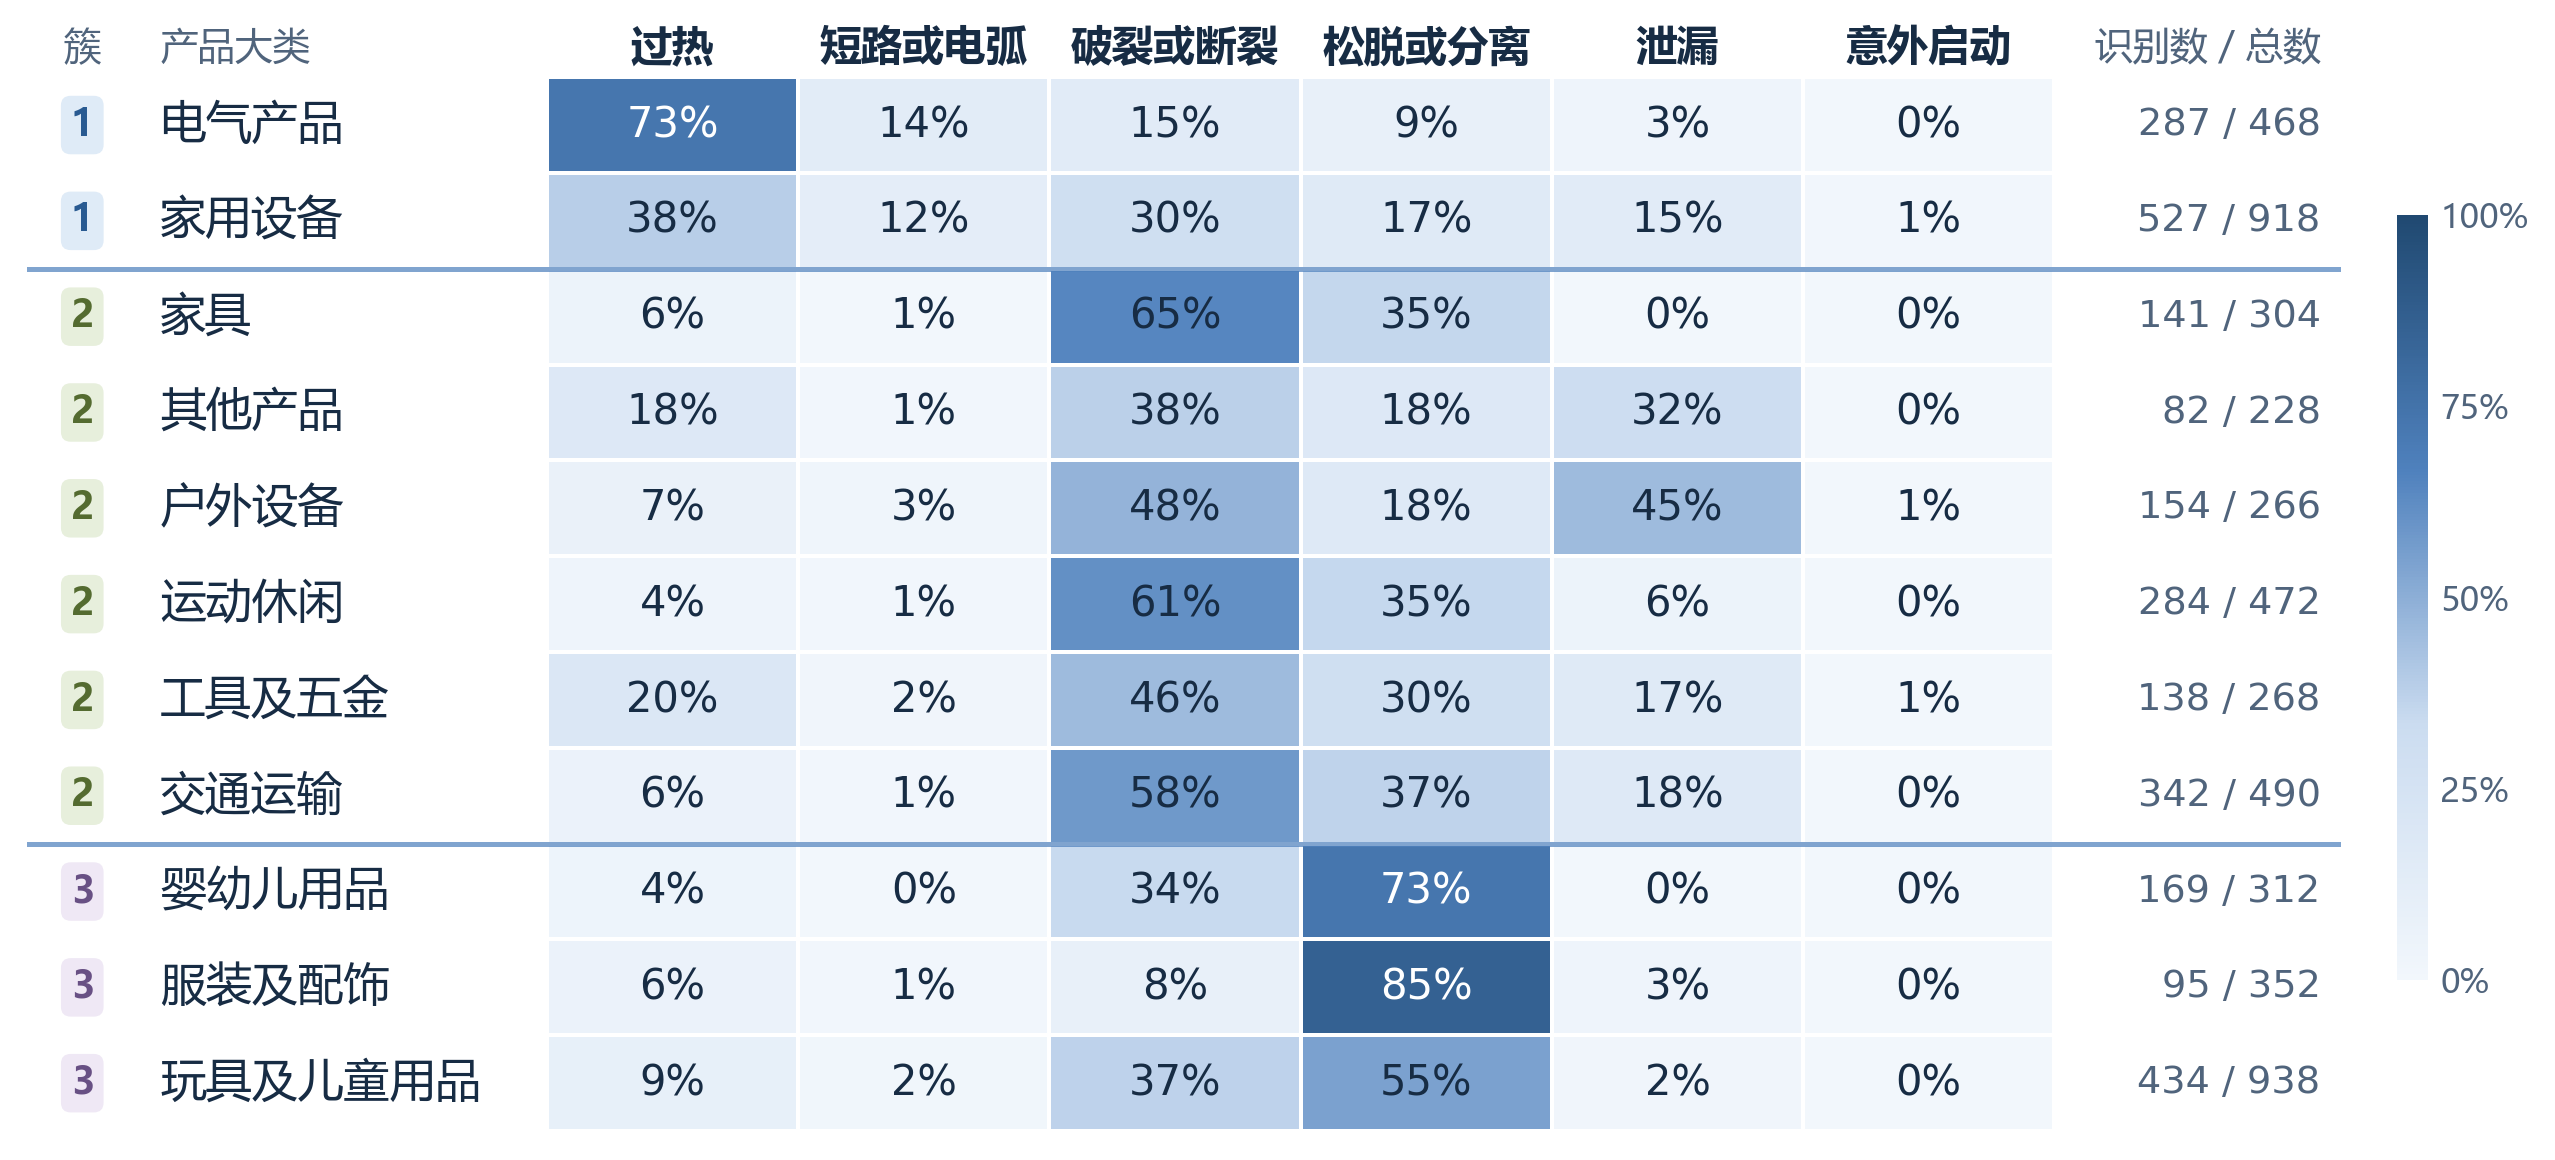

In [11]:
def profiles_chart(categories):
    rows = sorted(categories, key=lambda row: row["cluster"])
    profiles = np.array([row["profile"] for row in rows])
    cmap = LinearSegmentedColormap.from_list("lecture_blue", ["#F2F7FC", "#CBDCF0", BLUE, "#204971"])
    fig, ax = plt.subplots(figsize=(8.55, 4.18))
    fig.subplots_adjust(left=.025, right=.927, bottom=.058, top=.90)
    mesh = ax.pcolormesh(np.arange(7)-.5, np.arange(len(rows)+1)-.5, profiles,
                         cmap=cmap, vmin=0, vmax=1, edgecolors="white", linewidth=.9)
    ax.set(xlim=(-2.57, 6.64), ylim=(len(rows)-.48, -.5))
    ax.set_xticks([])
    ax.set_yticks([])
    ax.spines[:].set_visible(False)
    headings = ["过热", "短路或电弧", "破裂或断裂", "松脱或分离", "泄漏", "意外启动"]
    for x, heading in enumerate(headings):
        ax.text(x, -.80, heading, ha="center", va="center", color=INK, fontsize=10, weight="semibold")
    for x, heading, align in ((-2.35, "簇", "center"), (-2.04, "产品大类", "left"), (6.56, "识别数 / 总数", "right")):
        ax.text(x, -.80, heading, va="center", ha=align, color=MUTED, fontsize=9)
    for i, r in enumerate(rows):
        cluster = r["cluster"]
        if i and rows[i-1]["cluster"] != cluster:
            ax.axhline(i-.5, color=BLUE, linewidth=1.2, alpha=.72)
        ax.text(-2.35, i, str(cluster+1), ha="center", va="center", color=CLUSTER_INK[cluster],
                weight="bold", fontsize=9, bbox={"boxstyle": "round,pad=.26", "fc": CLUSTER_TINT[cluster], "ec": "none"})
        ax.text(-2.04, i, CATEGORY_NAMES[r["category"]], ha="left", va="center", fontsize=11)
        ax.text(6.56, i, f"{r['coded_early']} / {r['early']}", ha="right", va="center",
                fontfamily="DejaVu Sans", fontsize=9.2, color=MUTED)
        for j, value in enumerate(profiles[i]):
            rgb = to_rgb(cmap(value))
            linear = [c/12.92 if c <= .04045 else ((c+.055)/1.055)**2.4 for c in rgb]
            luma = sum(c*w for c, w in zip(linear, (.2126, .7152, .0722)))
            ax.text(j, i, f"{value:.0%}", ha="center", va="center", fontfamily="DejaVu Sans",
                    weight="medium", color="white" if luma < .18 else INK)
    cax = fig.add_axes([.949, .18, .012, .61])
    scale = fig.colorbar(mesh, cax=cax, ticks=np.linspace(0, 1, 5), format=PercentFormatter(xmax=1))
    scale.outline.set_visible(False)
    scale.ax.tick_params(labelsize=8, length=0, pad=3, colors=MUTED)
    save(fig, "figure1_profiles.png")

profile_rows = [{"category": t, "cluster": int(main_model.labels_[i]), "profile": profiles[i].tolist(),
                 "coded_early": int(coded[i]), "early": int(totals[i])} for i, t in enumerate(categories)]
profiles_chart(profile_rows)

*图 1  大类失效比例及分组。深色表示失效比例更高，右列为建模期内识别到失效的案例数 / 总数。*

家用设备与电气产品聚为一组。服装及配饰、玩具及儿童用品和婴幼儿用品聚为一组。其余六个大类在第三组。这里的同簇关系由六类关键词比例决定，组内可包含结构和使用情境差异较大的产品。

K 取 2、3、4、5 时，平均轮廓系数依次为 0.357、0.413、0.389、0.349[4]。平均连接层次聚类和将比例分母改为本类全部建模期召回，均得到与主实验相同的三簇分组，调整兰德指数（ARI）均为 1.000。两项敏感性对照的预测与主 B 一致。将 K 改为 2 后，B 的 micro-F1 为 0.365。

K-means 的输入是 11 个产品大类的历史失效比例向量。轮廓系数和 ARI 用于说明分组，危险提示的效果另外用回测期召回评估。

#### 失效构成相近的产品，危险构成也相近吗？

只用建模期数据，将 11 个大类两两配对。第一步计算每对大类六维失效比例的欧氏距离，沿用 K-means 的输入。第二步将每类各危险的出现次数除以该类的危险标签出现总次数，使其和为 1，再用 Jensen–Shannon 距离衡量两类危险构成的差异（自然对数，距离为散度的平方根）。距离越小，构成越接近。每个类别对等权。危险标签只用于检验分组后的相似程度，未用于拟合 K-means。

In [12]:
from scipy.spatial.distance import pdist

failure_dist = pdist(profiles, metric="euclidean")
hazard_freq = np.array([[float(rates[t][h]) for h in labels] for t in categories])
hazard_mix = hazard_freq / hazard_freq.sum(axis=1, keepdims=True)
hazard_dist = pdist(hazard_mix, metric="jensenshannon")
category_pairs = list(combinations(range(len(categories)), 2))
same_cluster = np.array([main_model.labels_[i] == main_model.labels_[j] for i, j in category_pairs])
distance_r = np.corrcoef(failure_dist, hazard_dist)[0, 1]
show_table("建模期内各类别对的危险构成距离", ["类别关系", "类别对数", "平均危险距离"],
           [(name, int(mask.sum()), f"{hazard_dist[mask].mean():.3f}")
            for name, mask in (("同簇", same_cluster), ("跨簇", ~same_cluster))])
print(f"全部 {len(category_pairs)} 对的失效距离与危险距离相关系数 r = {distance_r:.3f}")

类别关系,类别对数,平均危险距离
同簇,19,0.433
跨簇,36,0.545


全部 55 对的失效距离与危险距离相关系数 r = 0.465


同簇的 19 对平均危险距离为 0.433，跨簇的 36 对为 0.545。两种距离的相关系数为 0.465，说明失效构成较接近的类别，其历史危险构成往往也较接近。55 对共享同样的 11 个大类，因此这些数字用于描述关联。对设计师而言，清单只容得下两三项时，仍要检验借用其他类别的比例会把哪种危险推到前面。

### 5.2 从同簇类别算到危险提示：运动休闲类

以火灾为例。先取出 K-means 分给运动休闲类的全部参考类别，再查看各类建模期召回中的火灾比例。每个参考类别在平均值中占同样的权重。下面同时输出计算结果和 A、B 的完整清单。

In [13]:
example_category = "SPORTS_RECREATION"
example_hazard = "FIRE"
peers = references[example_category]
peer_rows = []
for peer in peers:
    records = groups[peer]
    fire_count = sum(example_hazard in r["hazards"] for r in records)
    peer_rows.append((CATEGORY_NAMES[peer], f"{fire_count}/{len(records)}", f"{float(rates[peer][example_hazard]):.1%}"))
show_table("运动休闲类的同簇参考类别与建模期火灾比例", ["参考产品大类", "火灾召回数 / 本类召回数", "火灾比例"], peer_rows)

own_rate = rates[example_category][example_hazard]
peer_mean = mean(rates[peer][example_hazard] for peer in peers)
combined_rate = (own_rate + peer_mean) / 2
assert combined_rate == b[example_category][example_hazard]
print(f"火灾得分：本类 {float(own_rate):.1%}，其他 {len(peers)} 类平均 {float(peer_mean):.1%}，等权合并后 {float(combined_rate):.1%}。")
for method, scores in (("A", rates), ("B", b)):
    alerts, _ = choose(scores[example_category], prior, THRESHOLD)
    print(method, "提示", "、".join(HAZARD_NAMES[h] for h in alerts))

参考产品大类,火灾召回数 / 本类召回数,火灾比例
家具,30/304,9.9%
其他产品,104/228,45.6%
户外设备,136/266,51.1%
工具及五金,56/268,20.9%
交通运输,87/490,17.8%


火灾得分：本类 3.2%，其他 5 类平均 29.1%，等权合并后 16.1%。
A 提示 跌落、撞击伤害
B 提示 跌落、撞击伤害、火灾


运动休闲类自身的火灾比例为 3.2%。五个参考类别的平均值为 29.1%，其中户外设备为 51.1%。B 合并本类比例与五类平均值后得到 16.1%（按未舍入值计算），超过 15% 门槛。因此，A 提示的跌落和撞击伤害都保留，B 另外提示火灾。阈值提高到 0.20 时，火灾得分仍为 16.1%，清单恢复为原有两项。第 6 节再用回测数据检验，第三个位置给火灾能覆盖多少案例。

## 6 回测期结果与案例解释

表 5 汇总两种提示条件。固定两项用于在相同阅读负担下比较 A、B。0.15 阈值加最少两项用于模拟允许补充危险提示的场景。后续案例注明使用的提示条件。

In [14]:
schemes = {"global": dict.fromkeys(categories, global_rates), "A": rates, "B": b,
           "B_all_denominator": b_all, "B_k2": b_k2, "B_hierarchical": b_hier}
predicted = {m: {t: choose(score, prior, THRESHOLD)[0] for t, score in scores.items()}
             for m, scores in schemes.items()}
evaluation = {m: measure(late, predictions, labels) for m, predictions in predicted.items()}
fixed_two = {m: measure(late, {t: top_k(scores, prior, 2)
                              for t, scores in schemes[m].items()}, labels) for m in ("A", "B")}

rows = []
for case in sorted(late, key=lambda rec: (rec["year"], rec["id"], rec["subtype"])):
    t = case["subtype"]
    rows.append({
        **case, "modes": sorted(case["modes"]), "hazards": sorted(case["hazards"]),
        **{f"prediction_{m}": predicted[m][t] for m in ("global", "A", "B")},
        **{f"hit_{m}": bool(case["hazards"].intersection(predicted[m][t])) for m in ("global", "A", "B")},
    })
paired = Counter((r["hit_A"], r["hit_B"]) for r in rows)

category_rows = []
for i, t in enumerate(categories):
    category_rows.append({
        "category": t, "early": int(totals[i]), "late": len(late_groups[t]),
        "coded_early": int(coded[i]), "coded_late": sum(bool(c["modes"]) for c in late_groups[t]),
        "profile": profiles[i].tolist(), "cluster": int(main_model.labels_[i]),
        "references": references[t], **{m: predicted[m][t] for m in ("A", "B")},
        **{f"scores_{m}": {h: float(v) for h, v in schemes[m][t].items()} for m in ("A", "B")},
        **{f"hit_{m}": measure(late_groups[t], predicted[m], labels)["hit"] for m in ("A", "B")},
    })

late_predictions = rows
full_metrics = {"categories": category_rows, "evaluation": evaluation, "fixed_two": fixed_two,
                "threshold": float(THRESHOLD)}
summary = [("全局频率", evaluation["global"]), ("A 本类历史", evaluation["A"]),
           ("B 同簇借鉴", evaluation["B"]), ("A 固定两项", fixed_two["A"]), ("B 固定两项", fixed_two["B"])]

show_table('表 5  回测期危险预测及固定两项对照', ['方法', '命中记录', '记录命中率', '精确率', '标签召回率', 'micro-F1'],
           [(name, f"{r['hit']:,}/{r['n']:,}", f"{r['hit_rate']:.1%}", f"{r['precision']:.1%}",
             f"{r['recall']:.1%}", f"{r['f1']:.3f}") for name, r in summary])

assert [full_metrics["evaluation"][m]["hit"] for m in ("global", "A", "B")] == [710, 1049, 921]
assert [full_metrics["fixed_two"][m]["hit"] for m in ("A", "B")] == [973, 854]
macro = {m: mean(r[f"hit_{m}"] / r["late"] for r in full_metrics["categories"]) for m in ("A", "B")}
assert [f"{macro[m]:.1%}" for m in ("A", "B")] == ["70.0%", "58.4%"]
print(f"B 独有命中 {paired[False, True]} 条，A 独有命中 {paired[True, False]} 条。")
print(f"K = 2 时 B 的 micro-F1 为 {evaluation['B_k2']['f1']:.3f}。")

方法,命中记录,记录命中率,精确率,标签召回率,micro-F1
全局频率,"710/1,491",47.6%,15.9%,47.5%,0.238
A 本类历史,"1,049/1,491",70.4%,32.2%,70.3%,0.442
B 同簇借鉴,"921/1,491",61.8%,27.2%,61.8%,0.377
A 固定两项,"973/1,491",65.3%,32.7%,65.1%,0.435
B 固定两项,"854/1,491",57.3%,28.7%,57.2%,0.382


B 独有命中 14 条，A 独有命中 142 条。
K = 2 时 B 的 micro-F1 为 0.365。


固定两项时，A 多命中 119 条。使用 0.15 阈值时，B 有 14 条独有命中，A 有 142 条独有命中。下面分别检查外部权重和参考范围，再解释哪些危险被新增或漏掉。

图 2 先用各大类自己的回测期记录数计算命中率。再让 11 个大类各占相同权重，取这些命中率的平均值，A 为 70.0%，B 为 58.4%。因此，A 的优势在大类等权的口径下也成立。

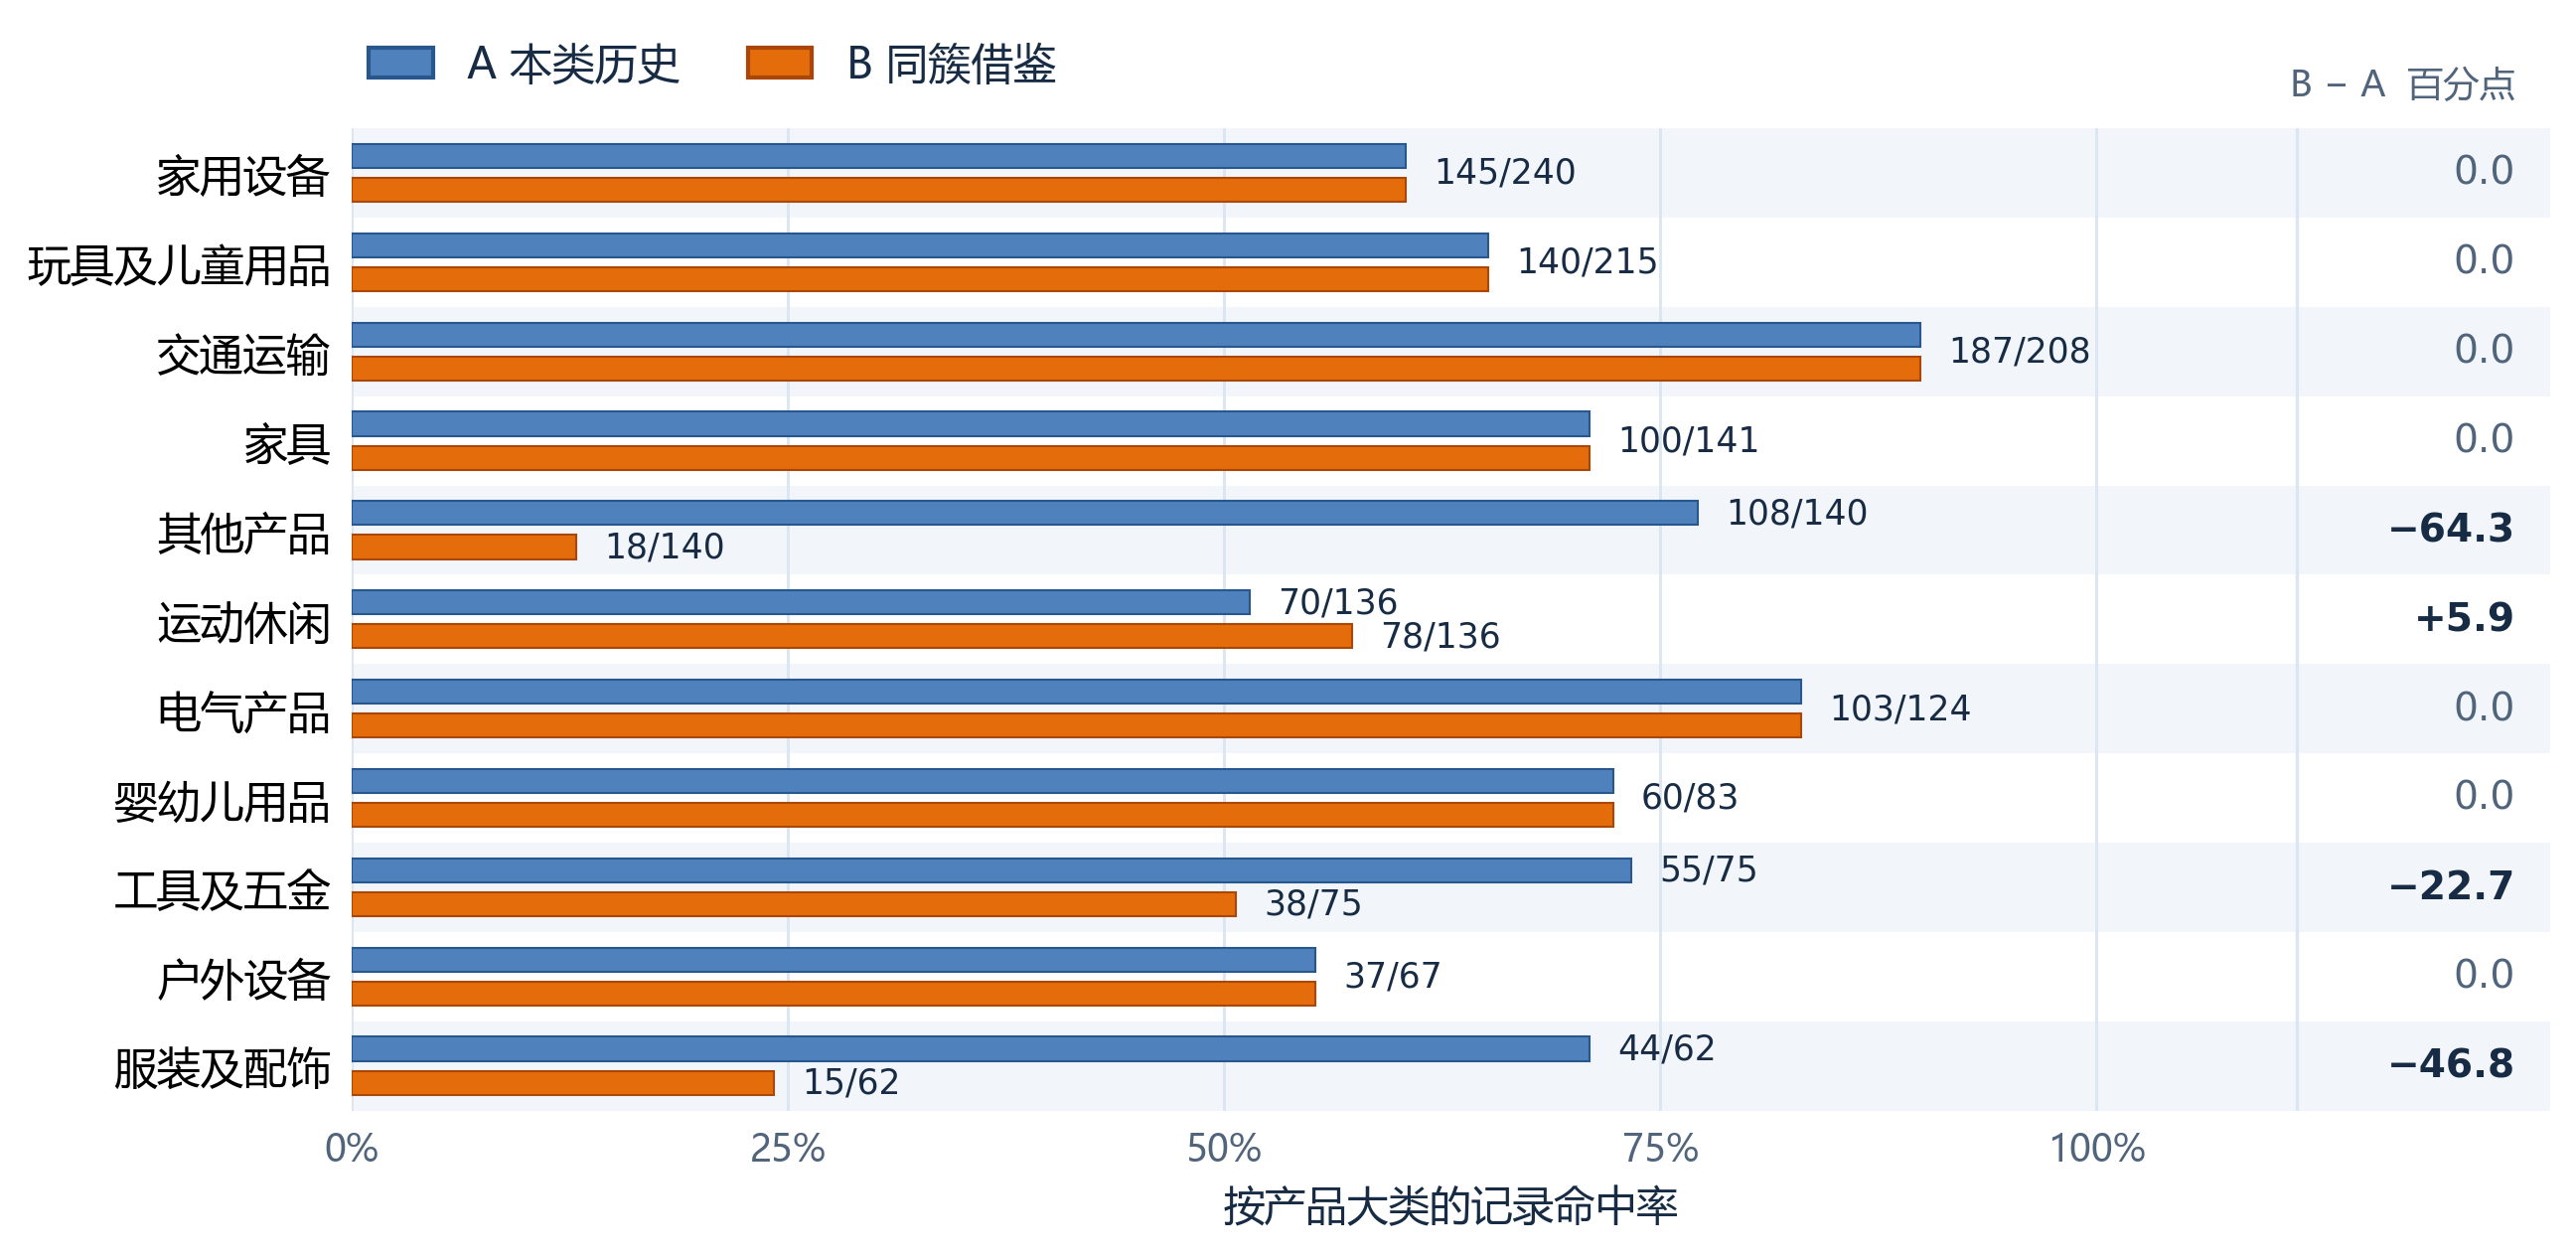

In [15]:
def comparison_chart(rows, xlabel, filename):
    fig, ax = plt.subplots(figsize=(8.55, 4.12), layout="constrained")
    y = np.arange(len(rows))
    for i in y[::2]:
        ax.axhspan(i-.5, i+.5, color="#F2F6FB", lw=0, zorder=0)
    for idx, ((_, fill, edge), offset) in enumerate(zip(SERIES, (-.19, .19)), start=1):
        values = [r[idx] / r[3] for r in rows]
        ax.barh(y+offset, values, height=.27, color=fill, edgecolor=edge, linewidth=.5, zorder=2)
        for position, value, row in zip(y, values, rows):
            if row[1] == row[2] and idx == 2:
                continue
            if row[1] != row[2]:
                position += offset
            ax.text(value+.016, position, f"{row[idx]}/{row[3]}", va="center", color=INK,
                    fontfamily="DejaVu Sans", fontsize=8.3)
    for i, row in enumerate(rows):
        delta = 100*(row[2]-row[1])/row[3]
        change = f"{delta:+.1f}".replace("-", "−") if delta else "0.0"
        ax.text(1.24, i, change, ha="right", va="center", fontfamily="DejaVu Sans", fontsize=9.4,
                color=INK if delta else MUTED, weight="bold" if delta else "normal")
    ax.text(1.24, 1.024, "B − A  百分点", transform=ax.get_xaxis_transform(), color=MUTED,
            ha="right", va="bottom", fontsize=8.7)
    ax.set_yticks(y, [row[0] for row in rows], fontsize=10.5)
    ax.set(xlim=(0, 1.26), ylim=(len(rows)-.5, -.5), xlabel=xlabel)
    ax.set_xticks(np.linspace(0, 1, 5))
    ax.xaxis.set_major_formatter(PercentFormatter(xmax=1))
    ax.spines[:].set_visible(False)
    ax.tick_params(axis="both", length=0, pad=5)
    ax.tick_params(axis="x", labelsize=9, labelcolor=MUTED)
    ax.grid(axis="x", color=GRID, linewidth=.7)
    ax.set_axisbelow(True)
    ax.axvline(1.115, color=GRID, lw=.8)
    ax.legend(handles=[Patch(facecolor=fill, edgecolor=edge, label=label) for label, fill, edge in SERIES],
              loc="lower left", bbox_to_anchor=(0, 1.023), ncols=2, frameon=False, borderaxespad=0,
              fontsize=10.3, handlelength=1.5, columnspacing=1.6)
    save(fig, filename)

categories_by_size = sorted(category_rows, key=lambda r: -r["late"])
comparison_chart([(CATEGORY_NAMES[r["category"]], r["hit_A"], r["hit_B"], r["late"]) for r in categories_by_size],
                 "按产品大类的记录命中率", "figure2_category_hits.png")

*图 2  采用 0.15 阈值时各产品大类的回测期命中率。条旁为命中数 / 评价数，右列为命中率之差。*

#### 用完整建模期得分复核阈值敏感性

表 2 回答如何在建模期内选阈值。下表固定用截至 2018 年的数据拟合得到的 A、B 得分和同一批回测记录，逐一代入原有六个阈值。观察整体结果和运动休闲类的火灾提示能否同时保持。

In [16]:
threshold_rows = []
for point in curve:
    q = Fraction(str(point["threshold"]))
    lists = {m: {t: choose(s, prior, q)[0] for t, s in schemes[m].items()} for m in ("A", "B")}
    a_result, b_result = (measure(late, lists[m], labels) for m in ("A", "B"))
    changed_categories = sum(set(lists["A"][t]) != set(lists["B"][t]) for t in categories)
    fire_added = "FIRE" in set(lists["B"]["SPORTS_RECREATION"]) - set(lists["A"]["SPORTS_RECREATION"])
    threshold_rows.append((f"{float(q):.2f}", a_result["hit"], f"{a_result['f1']:.3f}",
                           b_result["hit"], f"{b_result['f1']:.3f}", changed_categories,
                           "是" if fire_added else "否"))
show_table("表 5b  候选阈值在同一回测集上的表现",
           ["阈值", "A 命中", "A micro-F1", "B 命中", "B micro-F1", "清单不同的大类数", "运动休闲新增火灾"],
           threshold_rows)

阈值,A 命中,A micro-F1,B 命中,B micro-F1,清单不同的大类数,运动休闲新增火灾
0.10,1081,0.415,1017,0.360,8,是
0.15,1049,0.442,921,0.377,4,是
0.20,973,0.435,910,0.390,3,否
0.25,973,0.435,854,0.382,2,否
0.30,973,0.435,854,0.382,2,否
0.35,973,0.435,854,0.382,2,否


六档下大类 A 的命中数与 micro-F1 均较高。运动休闲类的表现随阈值改变：0.10 和 0.15 下 B 补入火灾，从 0.20 起这项补充消失。阈值 0.10 还说明了两项指标的区别：清单更长时，A 命中 1,081 个组合，但多出的提示使 micro-F1 低于主方案。

### 6.1 验证外部权重与参考范围

固定每个组合给两项提示，并在同一批 1,491 个回测期组合上比较。改变外部权重时保持同簇参考范围，验证参考范围时将权重固定为 50%。另列全局频率基线，保证阅读预算一致。此对照用于解释主结果。

In [17]:
train, test, group = early, late, groups
by_category = rates

cluster = {r["category"]: r["cluster"] for r in full_metrics["categories"]}

global_scores = global_rates

global_list = top_k(global_scores, prior, 2)
fixed_two_checks = {"全局频率": measure(test, dict.fromkeys(group, global_list), labels)}
top_two = {}
for name, alpha, same_cluster in (("A 本类历史", Fraction(0), True),
                                   ("B 同簇 10%", Fraction(1, 10), True),
                                   ("B 同簇 25%", Fraction(1, 4), True),
                                   ("B 同簇 50%", Fraction(1, 2), True),
                                   ("全部其他类 50%", Fraction(1, 2), False)):
    alarms = {}
    for t, own in by_category.items():
        others = [s for s in group if s != t and (not same_cluster or cluster[s] == cluster[t])]
        scores = {h: (1-alpha)*v + alpha*sum(by_category[s][h] for s in others)/len(others)
                  if others else v for h, v in own.items()}
        alarms[t] = top_k(scores, prior, 2)
    top_two[name] = alarms
    fixed_two_checks[name] = measure(test, alarms, labels)
assert [(d["hit"], f"{d['f1']:.3f}") for d in fixed_two_checks.values()] == [
    (567, "0.253"), (973, "0.435"), (973, "0.435"), (973, "0.435"), (854, "0.382"), (849, "0.380")]

show_table('表 6  固定两项提示的权重与参考范围对照', ['方法与外部权重', '命中记录', 'micro-F1'],
           [(name, f"{d['hit']:,}/{d['n']:,}", f"{d['f1']:.3f}") for name, d in fixed_two_checks.items()])
for name in ("B 同簇 10%", "B 同簇 25%"):
    changed_count = sum(set(top_two[name][t]) != set(top_two["A 本类历史"][t]) for t in group)
    print(f"{name}：与 A 的前两项危险集合不同的大类有 {changed_count}/{len(group)} 个。")
    assert changed_count == 0

方法与外部权重,命中记录,micro-F1
全局频率,"567/1,491",0.253
A 本类历史,"973/1,491",0.435
B 同簇 10%,"973/1,491",0.435
B 同簇 25%,"973/1,491",0.435
B 同簇 50%,"854/1,491",0.382
全部其他类 50%,"849/1,491",0.380


B 同簇 10%：与 A 的前两项危险集合不同的大类有 0/11 个。
B 同簇 25%：与 A 的前两项危险集合不同的大类有 0/11 个。


固定两项时，10% 和 25% 外部权重在 11 个大类中都保留了 A 的前两项危险集合。权重提高到 50% 后，同簇参考比参考全部其他类多命中 5 条，两种方案的命中数都低于 A。

再检验原阈值方案中各类清单长度不同的影响。先记录 B 按建模期得分为每一类给出几项，再让 A 按本类历史排序填写同样多的位置。整个过程只用已确定的清单长度和建模期得分，最后用回测标签计分。

In [18]:
matched_a = {}
for category, scores in rates.items():
    budget = len(predicted["B"][category])
    matched_a[category] = top_k(scores, prior, budget)

matched_metrics = measure(late, matched_a, labels)
b_metrics = evaluation["B"]
assert matched_metrics["prompts"] == b_metrics["prompts"]
show_table("表 6b  各大类提示数与 B 逐类相同的对照", ["危险排序", "提示总数", "命中记录", "micro-F1"],
           [(name, r["prompts"], f"{r['hit']:,}/{r['n']:,}", f"{r['f1']:.3f}")
            for name, r in (("A 本类历史", matched_metrics), ("B 同簇借鉴", b_metrics))])

危险排序,提示总数,命中记录,micro-F1
A 本类历史,3401,"1,068/1,491",0.437
B 同簇借鉴,3401,"921/1,491",0.377


在同样的 3,401 次标签提示下，本类排序多命中 147 个组合。再将原阈值方案的回测记录按公告年份分开，观察总体结果是否由某一年主导。

In [19]:
annual_rows = []
for year in sorted({r["year"] for r in late}):
    records = [r for r in late if r["year"] == year]
    annual_a = measure(records, predicted["A"], labels)
    annual_b = measure(records, predicted["B"], labels)
    annual_rows.append((year, len(records), f"{annual_a['f1']:.3f}", f"{annual_b['f1']:.3f}"))
show_table("表 6c  原阈值方案的逐年回测", ["公告年份", "编号 × 大类", "A micro-F1", "B micro-F1"], annual_rows)

公告年份,编号 × 大类,A micro-F1,B micro-F1
2019,224,0.438,0.361
2020,245,0.482,0.367
2021,204,0.464,0.397
2022,254,0.430,0.371
2023,285,0.421,0.386
2024,279,0.426,0.382


2019–2024 年逐年比较，六年中 A 的 micro-F1 均高于 B。各年都使用截至 2018 年确定的同一组模型与提示规则。

### 6.2 火灾补充与中毒漏报

比较 A 与 B 的标签集合，记录新增或被替换的危险，再查看同一批回测公告的命中数变化。

In [20]:
changed = [r for r in category_rows if set(r["A"]) != set(r["B"])]
def hazard_text(hazards):
    return "、".join(HAZARD_NAMES[h] for h in hazards)

show_table('表 7  同簇借鉴改变提示的产品大类', ['产品大类', 'A 提示', 'B 提示', '命中数变化'],
           [(CATEGORY_NAMES[r["category"]], hazard_text(r["A"]), hazard_text(r["B"]),
             f"{r['hit_A']} → {r['hit_B']} / {r['late']}") for r in sorted(changed, key=lambda r: r["hit_B"]-r["hit_A"])])

产品大类,A 提示,B 提示,命中数变化
其他产品,火灾、中毒,火灾、跌落,108 → 18 / 140
服装及配饰,窒息或噎塞、灼伤,窒息或噎塞、跌落,44 → 15 / 62
工具及五金,割伤、火灾、撞击伤害,火灾、割伤、跌落,55 → 38 / 75
运动休闲,跌落、撞击伤害,跌落、撞击伤害、火灾,70 → 78 / 136


其他产品是命中降幅最大的大类。该类有 91 个回测期中毒标签。同簇平均把中毒从 0.180 降到 0.100，将跌落推至 0.155，导致提示由中毒改为跌落。2019 年编号 8499 的原始记录描述儿童可能接触局部麻醉凝胶，标注中毒。A 命中，B 漏报。即使从回测期样本剔除异质性较强的其他产品，A 仍命中 941/1,351，B 命中 903/1,351。

运动休闲类的火灾得分从 3.2% 升至 16.1%，越过 15% 门槛。提高到 20% 后，两份清单均只保留跌落和撞击伤害。B 同时改变了危险排序与清单长度。表 7b 先比较两项与三项，再把第三个位置分别交给 B 和 A 排名第三的危险。三行都使用同一批 136 条记录。

In [21]:
sport_category = "SPORTS_RECREATION"
sport_cases = late_groups[sport_category]
sport_comparisons = [("A 原阈值", predicted["A"]), ("B 原阈值", predicted["B"]), ("A 与 B 等长", matched_a)]
sport_table = []
for name, prompts in sport_comparisons:
    hazards = prompts[sport_category]
    result = measure(sport_cases, prompts, labels)
    sport_table.append((name, hazard_text(hazards), f"{result['hit']}/{result['n']}"))
show_table("表 7b  运动休闲类的第三项提示与命中记录", ["方案", "按得分排列的危险提示", "命中记录"], sport_table)

方案,按得分排列的危险提示,命中记录
A 原阈值,跌落、撞击伤害,70/136
B 原阈值,跌落、撞击伤害、火灾,78/136
A 与 B 等长,跌落、撞击伤害、安全装备失灵,89/136


前两项都是跌落和撞击伤害，命中 70/136。在 0.15 阈值下，B 把第三项给火灾，多覆盖 8 条，包括编号 8931 的运动计时器召回。A 把同一个位置给安全装备失灵，多覆盖 19 条。在这批公告上，保留火灾可以覆盖一批不同的案例，而按本类历史选择第三项能覆盖更多记录。图 3 展示四种危险的得分。

运动休闲额外命中的火灾召回编号 [8931, 8955, 9102, 9217, 9360, 9576, 9577, 9632]


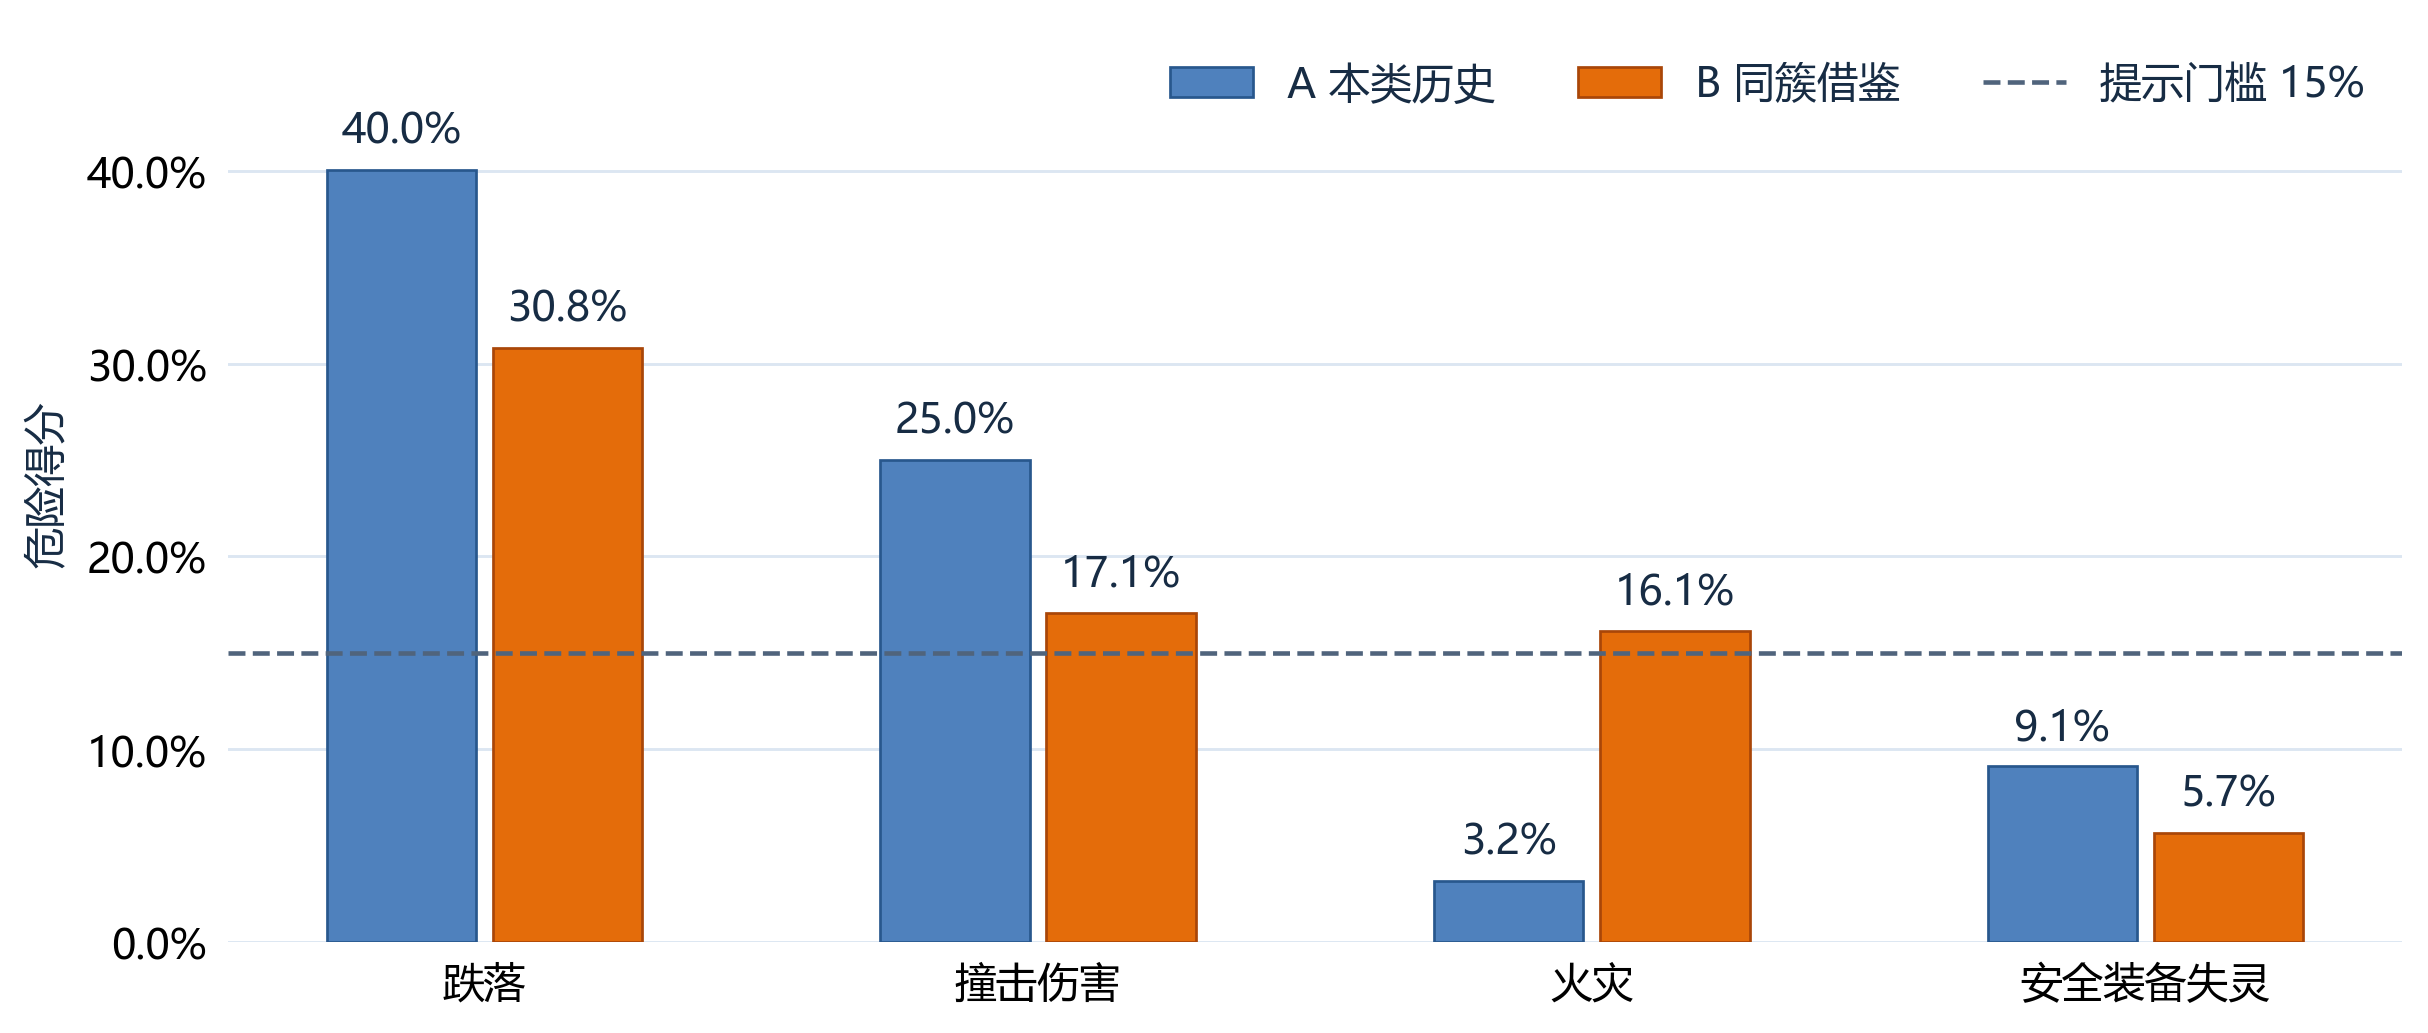

In [22]:
sport = "SPORTS_RECREATION"
sport_rows = [r for r in late_predictions if r["subtype"] == sport]
added = [r for r in sport_rows if r["hit_B"] and not r["hit_A"]]
assert len(sport_rows) == 136 and sum(r["hit_A"] for r in sport_rows) == 70
assert sum(r["hit_B"] for r in sport_rows) == 78 and len(added) == 8
assert all("FIRE" in r["hazards"] and "FIRE" in r["prediction_B"] for r in added)
assert 8931 in {r["id"] for r in added}
assert top_two["A 本类历史"][sport] == top_two["B 同簇 50%"][sport]

print("运动休闲额外命中的火灾召回编号", sorted(r["id"] for r in added))

def sports_fire_chart(result, threshold):
    hazards = ["FALLING", "IMPACT", "FIRE", "SAFETY_EQUIPMENT_MALFUNCTION"]
    x = np.arange(len(hazards))
    fig, ax = plt.subplots(figsize=(8.0, 3.35), layout="constrained")
    for method, offset, (label, fill, edge) in zip(("A", "B"), (-.15, .15), SERIES):
        values = [result[f"scores_{method}"][h] for h in hazards]
        bars = ax.bar(x + offset, values, width=.27, color=fill, edgecolor=edge, linewidth=.65, label=label)
        for bar, value in zip(bars, values):
            ax.text(bar.get_x() + bar.get_width()/2, value + .009, f"{value:.1%}",
                    ha="center", va="bottom", fontsize=10, color=INK)
    ax.axhline(threshold, color=MUTED, linewidth=1.1, linestyle="--", label="提示门槛 15%")
    ax.set_xticks(x, [HAZARD_NAMES[h] for h in hazards])
    ax.set_ylim(0, .475)
    ax.set_ylabel("危险得分")
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
    ax.spines[:].set_visible(False)
    ax.tick_params(axis="both", length=0, pad=5)
    ax.grid(axis="y", linewidth=.7, color=GRID)
    ax.set_axisbelow(True)
    handles, labels = ax.get_legend_handles_labels()
    ax.legend(handles[1:] + handles[:1], labels[1:] + labels[:1], frameon=False, loc="upper right", ncols=3)
    save(fig, "figure_sports_fire.png")

sports_result = next(r for r in category_rows if r["category"] == sport)
sports_fire_chart(sports_result, float(THRESHOLD))

*图 3  运动休闲类前两项及两种第三项选择的得分。虚线为 0.15 阈值。*

[CPSC 运动计时器召回原公告](https://www.cpsc.gov/Recalls/2021/Coulter-Ventures-Recalls-Rogue-Home-Timers-Due-to-Fire-Hazard-Sold-Exclusively-at-Rogue-Fitness)

### 6.3 各危险标签的漏报

按危险标签汇总所有大类的正确提示数，除以回测期中实际带有该标签的组合数。

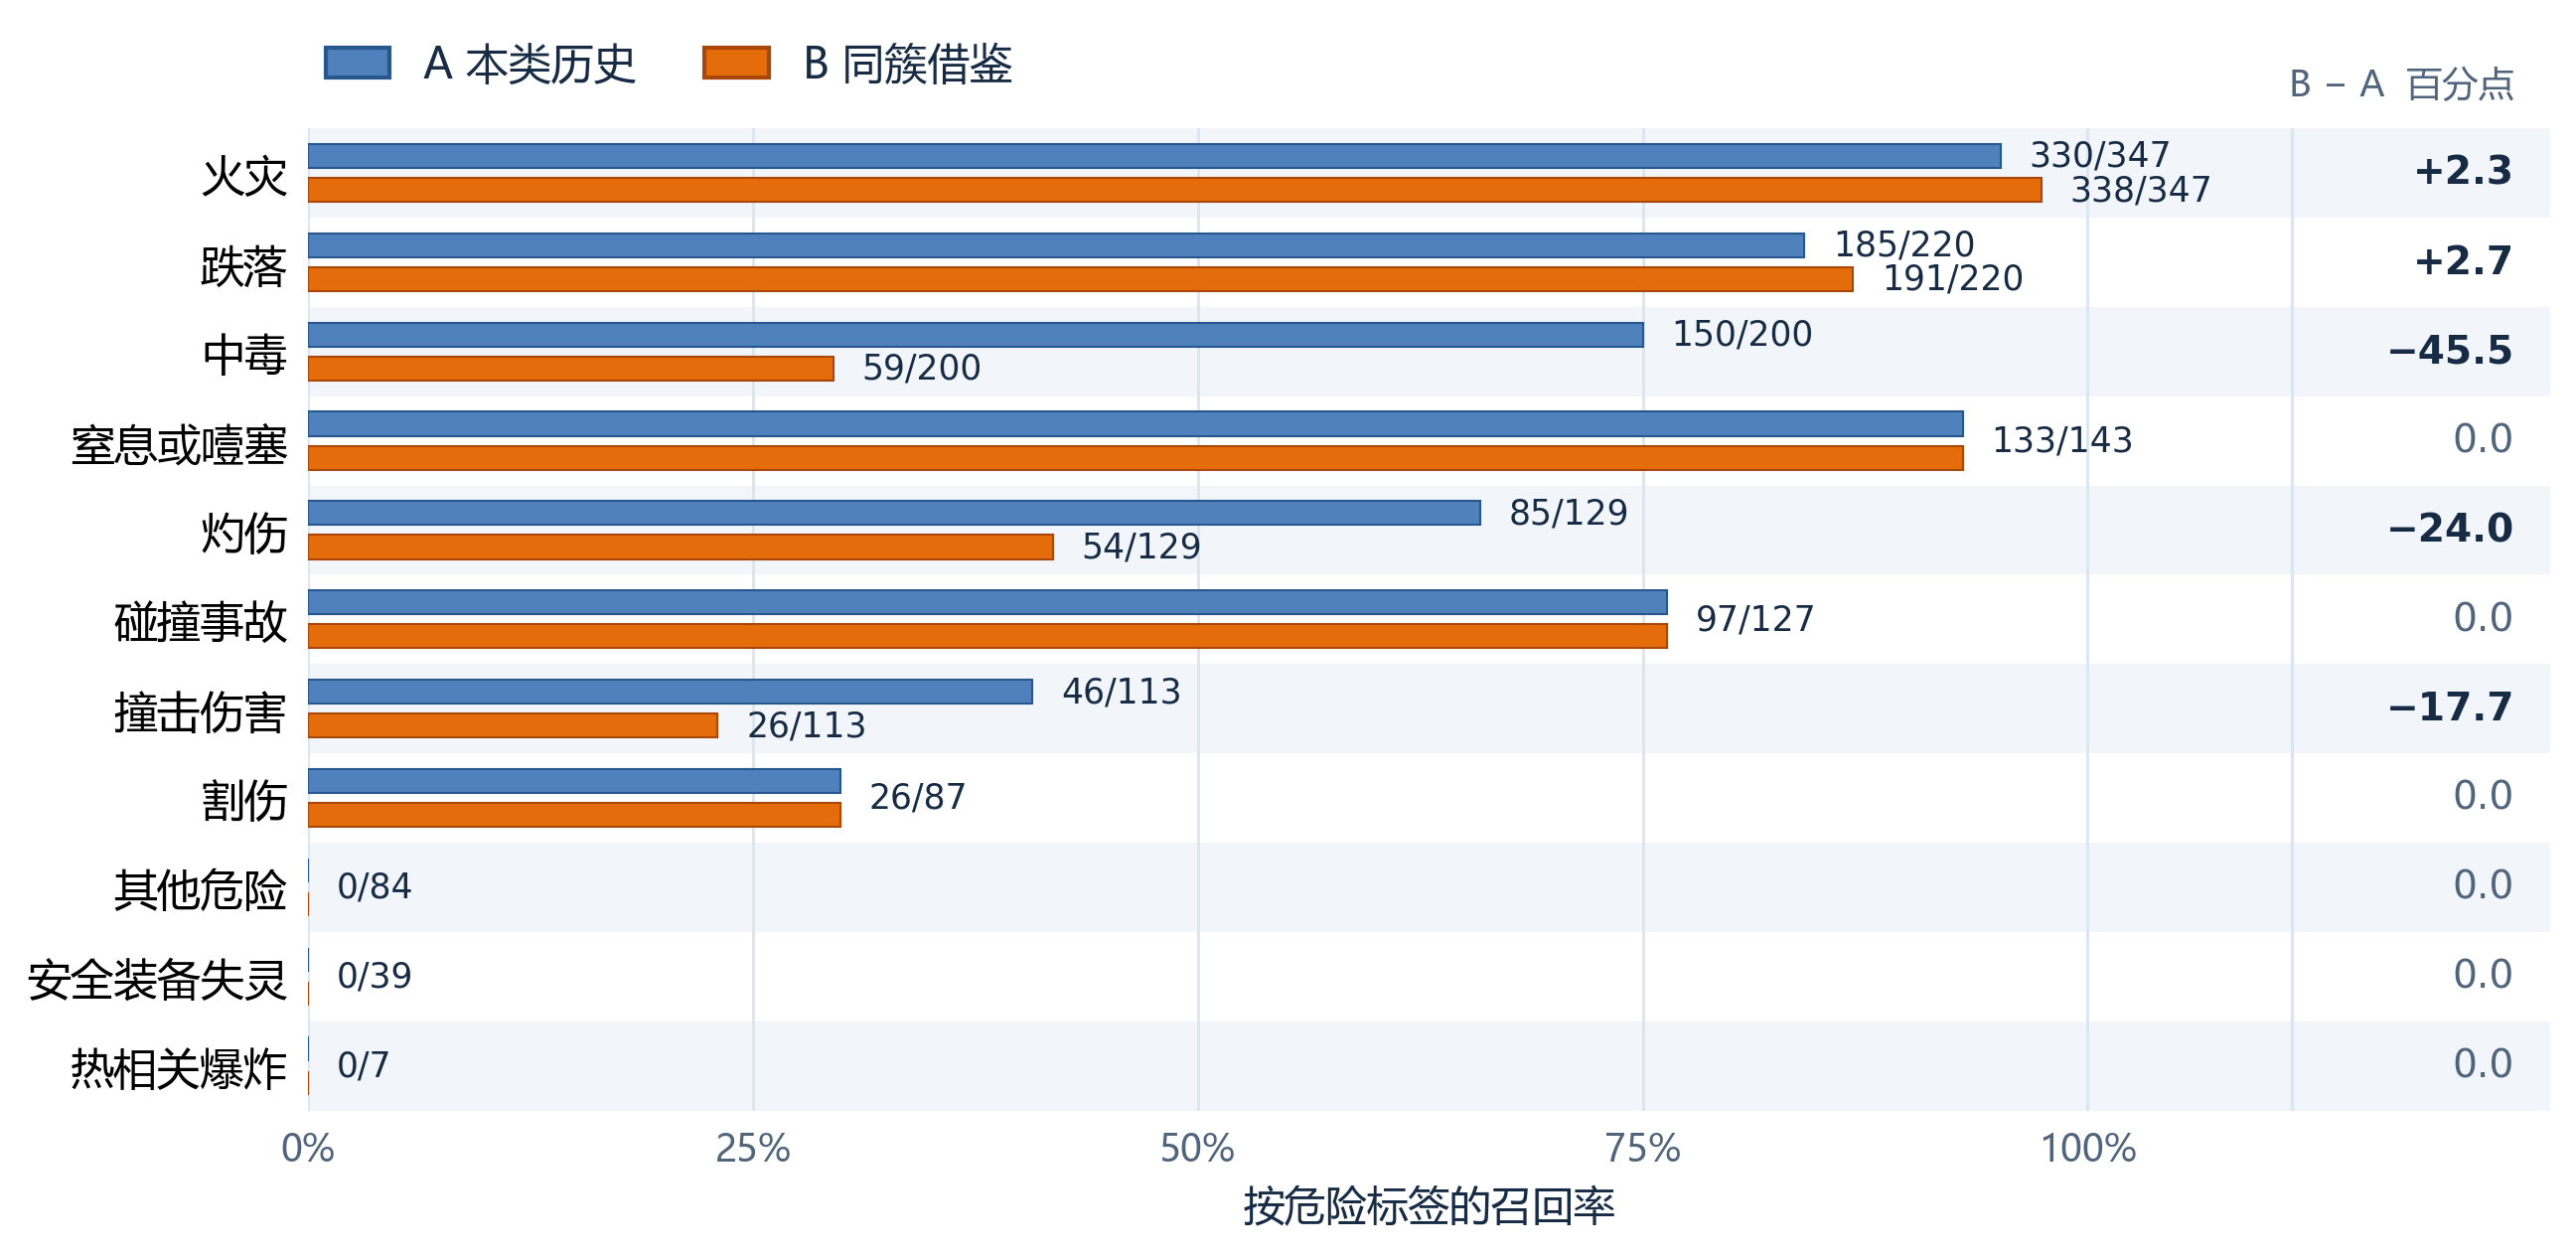

In [23]:
hazard_metrics_a, hazard_metrics_b = (evaluation[key]["metrics_by_hazard"] for key in ("A", "B"))
hazard_order = sorted(hazard_metrics_a, key=lambda h: -hazard_metrics_a[h]["n_ref"])
comparison_chart([(HAZARD_NAMES[h], hazard_metrics_a[h]["tp"], hazard_metrics_b[h]["tp"], hazard_metrics_a[h]["n_ref"]) for h in hazard_order],
                 "按危险标签的召回率", "figure3_hazard_recall.png")
assert len(regenerated_figures) == 4

*图 4  采用 0.15 阈值时各危险标签的召回率。条旁为正确提示数 / 标签数，右列为召回率之差。*

B 的中毒命中从 150/200 降至 59/200，灼伤从 85/129 降至 54/129，撞击伤害从 46/113 降至 26/113。火灾和跌落标签的命中分别增加 8 次和 6 次。

在原阈值清单下，两种方法均未命中 39 个安全装备失灵、7 个热相关爆炸和 84 个其他危险标签。这些漏报反映了用大类频率生成短清单对低排名危险的覆盖限制。

### 6.4 在相同公告上比较 A 与 B

同一召回可能涉及多个大类。为进行配对检验，按召回编号汇总两种方法的命中状态：一个编号只要在至少一个所属大类中命中该类的真实危险，就算该方法命中。双侧精确 McNemar 检验比较“A 独有命中”与“B 独有命中”的编号数。另对 micro-F1 做配对 bootstrap。每次有放回抽取召回编号，同一编号的全部大类和标签一起进入样本，用同一次抽样分别计算两种方法的 micro-F1。这样保留了主指标按「编号 × 大类 × 标签」计分的定义。

In [24]:
from scipy.stats import binomtest

def compare_hits_by_id(records, left, right):
    hit_by_id = defaultdict(lambda: [False, False])
    for record in records:
        flags = hit_by_id[record["id"]]
        for j, predictions in enumerate((left, right)):
            flags[j] |= bool(record["hazards"].intersection(predictions[record["subtype"]]))
    paired_counts = Counter(tuple(flags) for flags in hit_by_id.values())
    left_only = paired_counts[True, False]
    right_only = paired_counts[False, True]
    discordant = left_only + right_only
    p = binomtest(left_only, discordant, p=0.5).pvalue if discordant else 1.0
    return len(hit_by_id), left_only, right_only, p


def paired_f1_interval(records, left, right):
    # 按编号保留两种方法各自的 TP、FP、FN，重抽后重新计算总体 micro-F1。
    counts = defaultdict(lambda: np.zeros((2, 3), dtype=int))
    for record in records:
        actual = record["hazards"]
        for j, predictions in enumerate((left, right)):
            given = set(predictions[record["subtype"]])
            counts[record["id"]][j] += [len(given & actual), len(given - actual), len(actual - given)]
    by_id = np.array(list(counts.values()))
    rng = np.random.default_rng(42)
    differences = []
    for _ in range(50):
        sample = rng.integers(len(by_id), size=(100, len(by_id)))
        tp, fp, fn = by_id[sample].sum(axis=1).transpose(2, 0, 1)
        scores = 2 * tp / (2 * tp + fp + fn)
        differences.extend(scores[:, 0] - scores[:, 1])
    return np.quantile(differences, [0.025, 0.975])


pair_rows = []
for name, left, right in (("阈值 0.15", predicted["A"], predicted["B"]),
                          ("固定两项", top_two["A 本类历史"], top_two["B 同簇 50%"])):
    n_ids, left_only, right_only, p_value = compare_hits_by_id(late, left, right)
    pair_rows.append((name, n_ids, left_only, right_only, f"{p_value:.2g}"))
show_table("表 7c  大类提示的配对命中比较",
           ["方案", "回测编号", "仅 A 命中", "仅 B 命中", "精确双侧 p"], pair_rows)
f1_delta = evaluation["A"]["f1"] - evaluation["B"]["f1"]
f1_bounds = paired_f1_interval(late, predicted["A"], predicted["B"])
print(f"阈值 0.15 下 A 减 B 的 micro-F1 为 {f1_delta:.4f}，"
      f"配对 bootstrap 95% 百分位区间为 [{f1_bounds[0]:.4f}, {f1_bounds[1]:.4f}]。")

方案,回测编号,仅 A 命中,仅 B 命中,精确双侧 p
阈值 0.15,1486,142,14,7.7e-28
固定两项,1486,122,3,1.5e-32


阈值 0.15 下 A 减 B 的 micro-F1 为 0.0646，配对 bootstrap 95% 百分位区间为 [0.0547, 0.0743]。


主方案下，在 1,486 个不同的回测编号中，只有 A 命中的有 142 个，只有 B 命中的有 14 个。与等长提示对照结合，这解释了为什么个别新增的火灾命中不足以抵消其他遗漏。主方案的 micro-F1 差为 0.0646，5,000 次重抽的 95% 区间约为 [0.0547, 0.0743]。该区间以模型已拟合、召回编号可独立重抽为条件；未来年份的分布变化、同厂产品的相关性以及重新训练的波动都可能影响外推。

## 7 家用设备子类对照

第 4.3 节用交通运输建模样本说明，产品子类的构成会影响大类清单。这里换用家用设备，进一步在回测中检验已知子类时，提示能否覆盖更多后续召回。家用设备词典覆盖 15 个预定义子类，筛得 354 起召回。其中 11 个子类满足建模条件，对应 73 起回测期召回。按召回编号将这 73 起与全量模型的家用设备预测逐条对齐，核对两份记录的真实危险标签完全一致。

In [25]:
TYPES = {
    '热水器': r'water heaters?',
    '锅炉': r'boilers?',
    '壁炉': r'fireplaces?',
    '暖炉': r'furnaces?',
    '取暖器': r'heaters?',
    '空调及热泵': r'air conditioners?|heat pumps?',
    '除湿机': r'dehumidifiers?',
    '冰箱及冷柜': r'refrigerators?|freezers?',
    '洗碗机': r'dishwashers?',
    '洗衣机': r'washing machines?|clothes washers?',
    '咖啡及浓缩咖啡设备': r'coffee\s?(?:makers?|brewers?|machines?|centers?)|espresso (?:makers?|machines?)',
    '压力锅': r'pressure cookers?',
    '灶具及烤箱': r'ranges?|ovens?|cooktops?',
    '风扇': r'fans?',
    '吸尘器': r'vacuums?',
}

EXCLUDE = re.compile(
    r'\b(?:range hoods?|oven mitts?|oven gloves?|vacuum flasks?|dutch ovens?|oven liners?|'
    r'oven rack guards?|cooktop fire suppressors?|drip pans?|fire suppression devices?|oven cleaner|'
    r'gas control valves for|water heater (?:gas )?temperature controls?|spas and hot tubs|'
    r'fireplace screens?|fireplace gas valves?|gas valves used in|remote control kits?|'
    r'attachment tools?|fan electric motor|coil drain pans?|boiler (?:operating|control|controller)|'
    r'control units for boilers|service kit|accessory (?:electric )?heaters?|defrost heaters?|'
    r'(?:spa|pool|immersion) heaters?)\b', re.I)

def split_events(rows):
    events = {}
    for row in rows:
        event = events.setdefault(row["id"], {
            "id": row["id"], "year": row["year"], "subtype": row["subtype"],
            "hazards": set(), "modes": set(), "descriptions": [],
        })
        if (event["year"], event["subtype"]) != (row["year"], row["subtype"]):
            raise ValueError(f"Conflicting year or appliance family for {row['id']}")
        event["modes"].update(row["modes"])
        event["hazards"].update(row["hazards"])
        if row["description"] not in event["descriptions"]:
            event["descriptions"].append(row["description"])
    return list(events.values())


def grouped(events):
    return {t: [r for r in events if r["subtype"] == t]
            for t in TYPES if any(r["subtype"] == t for r in events)}


def validate_threshold(events):
    train = grouped([r for r in events if r["year"] <= 2013])
    names = eligible_families(train)
    validation = [r for r in events if 2014 <= r["year"] <= 2018 and r["subtype"] in names]
    prior = Counter(h for cases in train.values() for r in cases for h in r["hazards"])
    scores = {t: hazard_rates(train[t], sorted(prior)) for t in names}
    labels = sorted(set(prior) | {h for r in validation for h in r["hazards"]})
    curve = []
    for q in range(10, 36, 5):
        threshold = Fraction(q, 100)
        predictions = {t: choose(p, prior, threshold)[0] for t, p in scores.items()}
        result = measure(validation, predictions, labels)
        curve.append({k: result[k] for k in ("n", "tp", "fp", "fn", "f1", "recall",
                                             "average_prompts", "extra_events")})
        curve[-1]["threshold"] = float(threshold)
    selected = max(curve, key=lambda q: (q["f1"], -q["average_prompts"], -q["threshold"]))
    assert selected["threshold"] == float(THRESHOLD)
    return curve

按相同的入选标准，截至 2013 年有 8 个家电子类可用于建模期内的阈值验证，截至 2018 年有 11 个可用于最终建模。各阶段均用当时已知的召回计算全局频数并裁决得分并列。家电子类的验证同样选出 0.15。

在符合样本条件的家电子类上重复 A、B，再按召回编号配对大类与小类的提示。表 8 的四行使用相同的 73 起回测案例。

In [26]:
def run_home(raw):
    audit = []
    for source in raw:
        if "HOME_APPLIANCES" not in source["product_classification"]:
            continue
        name = source["product_name"]
        if EXCLUDE.search(name):
            continue
        families = matches(TYPES, name)
        if not families:
            continue
        description = source["recall_description"]
        audit.append({
            "id": source["recall_number"], "year": int(source["recall_date"][:4]),
            "subtype": families[0], "description": description,
            "modes": matches(MODES, description), "hazards": source["hazard_classification"],
        })
    events = split_events(audit)
    train = [row for row in events if row["year"] <= 2018]
    holdout = [row for row in events if row["year"] > 2018]
    by_family = grouped(train)
    names = eligible_families(by_family)
    test = [r for r in holdout if r["subtype"] in names and r["hazards"]]
    prior = Counter(h for row in train for h in row["hazards"])
    labels = sorted(prior)
    validation = validate_threshold(events)
    cooccurrence, _ = apriori([r for r in audit if r["year"] <= 2018], 1)
    assert cooccurrence == Counter((r["subtype"], h) for r in train for h in r["hazards"])
    rates = {t: hazard_rates(by_family[t], labels) for t in names}
    counts = np.array([[sum(mode in row["modes"] for row in by_family[t]) for mode in MODES]
                       for t in names])
    coded = np.array([sum(bool(row["modes"]) for row in by_family[t]) for t in names])
    with threadpool_limits(limits=1):
        clusters = fit_clusters(counts / coded[:, None], 3).labels_
    b_scores, references = scores_for_groups(names, clusters, rates, labels)
    all_labels = sorted(set(labels) | {h for row in test for h in row["hazards"]})
    scores = {"A": rates, "B": b_scores}
    predictions = {m: {t: choose(s, prior, THRESHOLD)[0] for t, s in body.items()}
                   for m, body in scores.items()}
    evaluation = {m: measure(test, prediction, all_labels) for m, prediction in predictions.items()}
    fixed_two = {m: measure(test, {t: pred[:2] for t, pred in prediction.items()}, all_labels)
                 for m, prediction in predictions.items()}
    return {"audit": audit, "events": len(events), "subtypes": len(names), "test": test,
            "evaluation": evaluation, "fixed_two": fixed_two, "predictions": predictions,
            "references": references, "validation": validation, "rates": rates}


home_metrics = run_home(raw)
home_coarse = {r["id"]: r for r in late_predictions if r["subtype"] == "HOME_APPLIANCES"}
matched = home_metrics["test"]
assert len({r["id"] for r in matched}) == len(matched) == 73
assert all(set(home_coarse[r["id"]]["hazards"]) == r["hazards"] for r in matched)
coarse_metrics = {
    method: measure(matched, dict.fromkeys({r["subtype"] for r in matched},
                                           home_coarse[matched[0]["id"]][f"prediction_{method}"]),
                    sorted(HAZARD_NAMES))
    for method in ("A", "B")
}

assert (home_metrics["events"], home_metrics["subtypes"]) == (354, 11)
assert [coarse_metrics[m]["hit"] for m in ("A", "B")] == [45, 45]
assert [home_metrics["evaluation"][m]["hit"] for m in ("A", "B")] == [57, 56]

show_table('表 8  同一批 73 起家用设备召回的大类与子类对照', ['预测依据', '命中事件', '事件命中率', 'micro-F1'],
           [(f"家用设备{level} {method}", f"{r['hit']}/{r['n']}", f"{r['hit_rate']:.1%}", f"{r['f1']:.3f}")
            for level, methods in (("大类", coarse_metrics), ("子类", home_metrics["evaluation"]))
            for method, r in methods.items()])

预测依据,命中事件,事件命中率,micro-F1
家用设备大类 A,45/73,61.6%,0.411
家用设备大类 B,45/73,61.6%,0.411
家用设备子类 A,57/73,78.1%,0.502
家用设备子类 B,56/73,76.7%,0.511


大类模型对这 73 起事件均提示火灾和灼伤。子类模型可以为锅炉提示中毒和火灾，贴合锅炉历史中较高的中毒比例（10/15），同时保留取暖器的火灾与灼伤提示。A 按子类预测多覆盖 12 起。在 0.15 阈值下，子类 B 命中 56 起，子类 A 命中 57 起。B 的提示较少，micro-F1 为 0.511，A 为 0.502。在每起都只给两条提示的比较中，小类 A 和 B 的 micro-F1 分别为 0.521 和 0.511。

这项对照评估的是现有两种粒度下可用的历史预测。小类模型由已识别的家电事件建模，大类模型使用更广的家电历史。结论适用于这批能够识别子类且有足够建模期记录的家用设备召回。

进一步将建模样本也固定为同一批家电召回，并让两种方法都给两项提示。

In [27]:
small_groups = home_metrics["predictions"]["A"].keys()
common_train = [r for r in split_events(home_metrics["audit"])
                if r["year"] <= 2018 and r["subtype"] in small_groups]
common_test = home_metrics["test"]
home_prior = Counter(h for r in common_train for h in r["hazards"])
home_labels = sorted(set(home_prior) | {h for r in common_test for h in r["hazards"]})
pooled = top_k(hazard_rates(common_train, home_labels), home_prior, 2)
simple = {t: top_k(hazard_rates(rows, home_labels), home_prior, 2)
          for t, rows in grouped(common_train).items()}
same_train_coarse = measure(common_test, dict.fromkeys(small_groups, pooled), home_labels)
same_train_fine = measure(common_test, simple, home_labels)
assert (len(common_train), len(common_test), same_train_coarse["hit"], same_train_fine["hit"]) == (241, 73, 45, 57)

print(f"建模 {len(common_train)} 起，回测 {len(common_test)} 起。大类命中 {same_train_coarse['hit']} 起，小类命中 {same_train_fine['hit']} 起。")
audit_events = split_events(home_metrics["audit"])
for cutoff in (2013, 2018):
    available = grouped([r for r in audit_events if r["year"] <= cutoff])
    print(f"截至 {cutoff} 年，符合建模条件的家电子类有 {len(eligible_families(available))} 个。")

建模 241 起，回测 73 起。大类命中 45 起，小类命中 57 起。
截至 2013 年，符合建模条件的家电子类有 8 个。
截至 2018 年，符合建模条件的家电子类有 11 个。


In [28]:
home_pair_rows = []
for name, left, right in (
    ("子类 A 对合并家电 A，固定两项、相同训练样本", simple, {t: pooled for t in simple}),
    ("子类 A 对子类 B，阈值 0.15", home_metrics["predictions"]["A"], home_metrics["predictions"]["B"]),
):
    n_ids, left_only, right_only, p_value = compare_hits_by_id(common_test, left, right)
    home_pair_rows.append((name, n_ids, left_only, right_only, f"{p_value:.5f}"))
show_table("表 8b  两种方法在同一批家电公告上各自找回哪些案例",
           ["前者与后者", "回测编号", "仅前者命中", "仅后者命中", "精确双侧 p"], home_pair_rows)

前者与后者,回测编号,仅前者命中,仅后者命中,精确双侧 p
子类 A 对合并家电 A，固定两项、相同训练样本,73,13,1,0.00183
子类 A 对子类 B，阈值 0.15,73,1,0,1.00000


为单独检验分类粒度，补充对照让两种方法共用 241 起建模期家电召回，且都只提示两项。在相同 73 起回测期召回上，按家电大类汇总仍命中 45 起，按小类分别统计命中 57 起。两种方法使用相同的样本和提示数，命中率由 61.6% 升到 78.1%。具体子类找回原来遗漏的 13 起，同时漏掉原先命中的 1 起（精确双侧 p = 0.00183）。单独比较子类 A 和 B 时，只有 1 起由 A 独有命中，B 独有 0 起（p = 1.00）。这 73 起公告不足以支持两种子类方法的命中率存在差异。对于这批有足够历史记录的家电，已知具体子类时，按子类生成清单更贴近后续公告中的危险。

### 7.1 空调及热泵的设计复查示例

空调及热泵建模期的 17 起召回中，15 起标注火灾，2 起标注灼伤。实验 A 优先提示火灾，补入灼伤，实验 B 给出相同的两项提示。评审空调时，可回查对应公告中的部件和失效过程，形成表 9 的复查问题。

In [29]:
ac_examples = {r["id"]: r for r in home_metrics["audit"] if r["subtype"] == "空调及热泵" and r["year"] <= 2018}
for recall_id, hazard in ((7984, "FIRE"), (448, "FIRE"), (8269, "BURN")):
    assert hazard in ac_examples[recall_id]["hazards"]

for recall_id in (7984, 448, 8269):
    print(recall_id, ac_examples[recall_id]["description"])

7984 The power cord plug can overheat, posing a fire hazard to consumers.
448 Condensation inside the units can splash onto the control board, causing short circuits and potential fire hazards.
8269 The outdoor fan motors can overheat, posing burn and fire hazards.


表 9  空调及热泵的历史案例与复查问题

<table style="border-collapse:collapse;width:100%;margin:auto;font-size:.95em">
<thead>
<tr>
<th style="background-color:#416DA3;color:#FFFFFF;text-align:left;width:15.20%;border:1px solid #D2DEEB;padding:6px 8px">危险</th>
<th style="background-color:#416DA3;color:#FFFFFF;text-align:center;width:39.49%;border:1px solid #D2DEEB;padding:6px 8px">案例依据</th>
<th style="background-color:#416DA3;color:#FFFFFF;text-align:center;width:45.31%;border:1px solid #D2DEEB;padding:6px 8px">相似结构的复查问题</th>
</tr>
</thead>
<tbody>
<tr>
<td style="background-color:#E8EFF8;color:#111827;text-align:left;width:15.20%;border:1px solid #D2DEEB;padding:6px 8px">火灾</td>
<td style="background-color:#E8EFF8;color:#111827;text-align:center;width:39.49%;border:1px solid #D2DEEB;padding:6px 8px">编号 7984。公告描述电源线插头过热。</td>
<td style="background-color:#E8EFF8;color:#111827;text-align:center;width:45.31%;border:1px solid #D2DEEB;padding:6px 8px">电源插头及其连接处在预期工况下的温升是否已复查？</td>
</tr>
<tr>
<td style="background-color:#F7FAFD;color:#111827;text-align:left;width:15.20%;border:1px solid #D2DEEB;padding:6px 8px">火灾</td>
<td style="background-color:#F7FAFD;color:#111827;text-align:center;width:39.49%;border:1px solid #D2DEEB;padding:6px 8px">编号 448。公告描述冷凝水接触控制板，引起短路。</td>
<td style="background-color:#F7FAFD;color:#111827;text-align:center;width:45.31%;border:1px solid #D2DEEB;padding:6px 8px">冷凝水的排水路径是否与控制板隔离？</td>
</tr>
<tr>
<td style="background-color:#E8EFF8;color:#111827;text-align:left;width:15.20%;border:1px solid #D2DEEB;padding:6px 8px">灼伤</td>
<td style="background-color:#E8EFF8;color:#111827;text-align:center;width:39.49%;border:1px solid #D2DEEB;padding:6px 8px">编号 8269。室外风机电机过热。</td>
<td style="background-color:#E8EFF8;color:#111827;text-align:center;width:45.31%;border:1px solid #D2DEEB;padding:6px 8px">风机电机的温升与周边可接触表面的温度是否已复查？</td>
</tr>
</tbody></table>

表 9 的复查问题来自具体公告，适用于具有相近结构和使用条件的产品。第 6 节的评价指标衡量危险标签的历史覆盖度。

## 8 补充分析 D：可见结构与危险的关联

### 8.1 从产品类别和结构进入查询

设计师输入产品类别和待查的可见结构。A 根据建模期本类历史给出排名前两项的危险，D 对这两项分别查询 2000–2024 年的历史公告。D 先为每项危险返回同类、同结构的案例线索。若匹配公告写明了失效部位和过程，就据此提出有适用条件的复查建议。同时报告同类占比差与区间，说明这一外观线索在召回资料中的集中程度和估计精度。第 8.6 节使用召回描述中的明确失效短语，量化产品子类、部件与失效方式和危险标签的关联。

分析使用有非空外观描述的原始行。沿用九类可见结构词典，从外观描述中滤去含危险或召回措辞的句子。按「召回编号 × 类别」去重。同一编号在该类别的任一有效行提到结构，即归入提到组，危险与结构的共现要求两者出现在同一有效行。其余有外观描述的编号构成未提到组。外观文字来自数据集的图像描述[1]，其中的遗漏和词典覆盖范围都会影响分组。

In [30]:
STRUCTURES = {
    "折叠或铰链": r"foldable|folding|fold[- ]lock|fold release|hinges?|hinged",
    "轮或脚轮": r"wheels|casters?|castors?",
    "束带或安全带": r"straps?|harness(?:es)?|seat belts?",
    "外部电源线或插头": r"power cords?|power cables?|electrical plugs?|power plugs?",
    "电池仓或其盖板": r"battery compartments?|battery covers?|battery doors?",
    "拉绳或珠链": r"drawstrings?|pull cords?|bead(?:ed)? chains?",
    "门或可开启盖": r"doors?|lids?|hinged covers?",
    "通风孔或格栅": r"air vents?|ventilation slots?|grilles?|grills?",
    "外露把手": r"handles?|handgrips?|grip bars?",
}


FEATURE_PATTERNS = {name: re.compile(rf"\b(?:{terms})\b", re.I) for name, terms in STRUCTURES.items()}


OUTCOME_WORDS = re.compile(
    r"\b(?:hazards?|recalled?|safety recall|risks? of|poses?|unsafe|danger(?:ous)?|"
    r"overheat\w*|chok\w*|strangl\w*|poison\w*|injur\w*|lacerat\w*|electrocut\w*|"
    r"amputat\w*|caught in|finger entrapment|fire hazard|burn hazard)\b", re.I,
)


def visible_structure(text):
    sentences = [s for s in re.split(r"[.!?;](?=\s|$)", text) if not OUTCOME_WORDS.search(s)]
    return {name for name, pattern in FEATURE_PATTERNS.items() if any(pattern.search(s) for s in sentences)}


def index_visual_cases(records):
    index = defaultdict(dict)
    for row in records:
        text = (row.get("visual_product_description") or "").strip()
        if not text:
            continue
        features = visible_structure(text)
        categories = list(row["product_classification"])
        if "HOME_APPLIANCES" in categories and not EXCLUDE.search(row["product_name"]):
            categories.extend(matches(TYPES, row["product_name"])[:1])
        for category in categories:
            case = index[category].setdefault(row["recall_number"],
                                              {"features": set(), "hazards": defaultdict(set)})
            case["features"].update(features)
            for hazard in row["hazard_classification"]:
                case["hazards"][hazard].update(features)
    return index


visual_cases = index_visual_cases(raw)
a_hazards = {category: prompts[:2] for category, prompts in alerts_a.items()}
a_hazards.update({category: prompts[:2] for category, prompts in home_metrics["predictions"]["A"].items()})
assert all(len(prompts) == len(set(prompts)) == 2 for prompts in a_hazards.values())

### 8.2 同类对照与不确定性

表中两组均来自同一时期、同一产品类别，分母分别为提到和未提到该结构的独立编号数。占比差为提到组减去未提到组的危险比例，以百分点表示。另列提升度供参照，分母为同类中有外观描述的全部编号的该危险比例。两组之一为空时，省略占比差和区间。

采用两独立比例差的 Newcombe–Wilson 方法计算逐项近似 95% 区间[5]。区间跨过零，表示在按独立编号取样的假设下，数据也与两组比例相近相容。区间没有校正多重比较、同厂产品的相关性或召回资料的选择偏差。以下比较用于探索线索，结果不能解释为结构导致事故的概率。

**怎样判断证据够不够？** 本研究对单个查询保留所有匹配案例。匹配数反映可供回查的公告数量，差值的区间宽度反映估计精度。具体建议须有公告所述的失效过程作为依据，并说明新设计需要具备哪些相似条件。若要量化建议的部位准确率，还需要独立的失效部位标注，用于逐例核对推荐位置。

In [31]:
from math import hypot, sqrt
from statistics import NormalDist

def wilson_bounds(hits, total):
    z = NormalDist().inv_cdf(0.975)
    proportion = hits / total
    scale = 1 + z**2 / total
    center = (proportion + z**2 / (2 * total)) / scale
    margin = z * sqrt(proportion * (1 - proportion) / total + z**2 / (4 * total**2)) / scale
    return center - margin, center + margin


def contrast(cases, structure, hazard):
    if structure not in STRUCTURES:
        raise ValueError(f"请选择词典中的结构：{list(STRUCTURES)}")
    mentioned = [rid for rid, case in cases.items() if structure in case["features"]]
    unmentioned = [case for case in cases.values() if structure not in case["features"]]
    ids = sorted(rid for rid in mentioned if structure in cases[rid]["hazards"].get(hazard, ()))
    x, n = len(ids), len(mentioned)
    y, m = sum(hazard in case["hazards"] for case in unmentioned), len(unmentioned)
    background = sum(hazard in case["hazards"] for case in cases.values())
    lift = (x / n) / (background / len(cases)) if n and background else None
    difference = interval = None
    if n and m:
        exposed, reference = x / n, y / m
        difference = exposed - reference
        lo1, hi1 = wilson_bounds(x, n)
        lo0, hi0 = wilson_bounds(y, m)
        interval = (difference - hypot(exposed - lo1, hi0 - reference),
                    difference + hypot(hi1 - exposed, reference - lo0))
    return dict(hazard=hazard, x=x, n=n, y=y, m=m, difference=difference,
                interval=interval, lift=lift, ids=ids)


def design_query(category, structure):
    if category not in a_hazards:
        raise ValueError(f"请选择 A 有两项提示的类别：{list(a_hazards)}")
    return [contrast(visual_cases[category], structure, h) for h in a_hazards[category]]


def fraction_text(x, n):
    return f"{x}/{n}（{x/n:.1%}）" if n else "0/0（无样本）"


def comparison_row(label, result):
    d, interval, lift = result["difference"], result["interval"], result["lift"]
    return (label, HAZARD_NAMES[result["hazard"]], fraction_text(result["x"], result["n"]),
            fraction_text(result["y"], result["m"]), f"{100*d:+.1f}" if d is not None else "—",
            f"[{100*interval[0]:+.1f}, {100*interval[1]:+.1f}]" if interval else "—",
            f"{lift:.2f}" if lift is not None else "—")


comparison_columns = ["查询范围", "A 提示", "提到组", "未提到组", "差（百分点）", "95% 区间（百分点）", "提升度"]

### 8.3 家电子类：同样是匹配，有多大额外信息？

输入空调及热泵的格栅，或冰箱及冷柜的门盖。下表对每个输入逐项列出 A 的两条危险，哪怕只有零至两起共现也保留。第 8.5 节提供可更换类别和结构的建议查询。

In [32]:
appliance_comparisons = []
for category, structure in (("空调及热泵", "通风孔或格栅"), ("冰箱及冷柜", "门或可开启盖")):
    for result in design_query(category, structure):
        appliance_comparisons.append(comparison_row(f"{category} / {structure}", result))
show_table("表 10  家电子类内的结构与危险", comparison_columns, appliance_comparisons)

查询范围,A 提示,提到组,未提到组,差（百分点）,95% 区间（百分点）,提升度
空调及热泵 / 通风孔或格栅,火灾,11/12（91.7%）,8/11（72.7%）,+18.9,"[-13.3, +49.0]",1.11
空调及热泵 / 通风孔或格栅,灼伤,0/12（0.0%）,3/11（27.3%）,-27.3,"[-56.6, +2.6]",0.00
冰箱及冷柜 / 门或可开启盖,火灾,8/16（50.0%）,3/6（50.0%）,+0.0,"[-38.2, +38.2]",1.00
冰箱及冷柜 / 门或可开启盖,撞击伤害,5/16（31.2%）,2/6（33.3%）,-2.1,"[-42.5, +31.9]",0.98


空调及热泵中，格栅提到组有 11/12 标注火灾，未提到组为 8/11。差为 +18.9 个百分点，95% 区间约为 [−13.3，+49.0] 个百分点。区间同时包含负值、零和较大的正值，说明格栅组的火灾标签比例是否更高仍有不确定性。已有 11 起匹配案例可回查，其中编号 7984 写明过热位置在电源插头。冰箱门盖对应的撞击伤害为 5/16 对 2/6，差为 −2.1 个百分点，区间约为 [−42.5，+31.9]。即使两组的历史占比相近，仍可能检索到有具体复查价值的公告。

为说明这套查询在资料库中的覆盖范围，另统计 A 的所有「类别 × 前两项危险」组合中，有多少至少匹配一项结构。此处沿用目录展示门槛：同一类至少 5 个编号提到结构，且至少 3 个与危险共现；再把共现门槛提高到 5 个。这两个计数门槛仅用于汇总目录覆盖。表 10 和表 11 的逐项查询均保留低频与零匹配结果。

In [33]:
coverage_rows = []
for scope_name, scope_categories in (("全量大类", list(alerts_a)),
                                      ("家电子类", list(home_metrics["predictions"]["A"]))):
    covered = Counter()
    total = sum(len(a_hazards[t]) for t in scope_categories)
    for category in scope_categories:
        for hazard in a_hazards[category]:
            comparisons = [contrast(visual_cases[category], f, hazard) for f in STRUCTURES]
            for minimum in (3, 5):
                covered[minimum] += any(r["n"] >= 5 and r["x"] >= minimum for r in comparisons)
    coverage_rows.append((scope_name, total, f"{covered[3]}/{total}", f"{covered[5]}/{total}"))
show_table("表 10b  A 固定两项提示的案例目录覆盖", ["范围", "类别 × 危险数", "共现 ≥3", "共现 ≥5"], coverage_rows)

范围,类别 × 危险数,共现 ≥3,共现 ≥5
全量大类,22,22/22,20/22
家电子类,22,11/22,9/22


### 8.4 分类粒度的敏感性：折叠或铰链与跌落

交通运输大类包含自行车、滑板车等产品。先取整个大类，再仅保留原始产品名称含独立英文词 bicycle 或 bicycles 的交通运输行，重新去重并比较。两个范围有重叠。这里沿用交通运输类 A 的危险提示；关键词子集只用于检查比较范围对占比差的影响。

In [34]:
bicycle_rows = [r for r in raw if "TRANSPORTATION" in r["product_classification"]
                and re.search(r"\bbicycles?\b", r["product_name"], re.I)]
bicycle_cases = index_visual_cases(bicycle_rows)["TRANSPORTATION"]
folding = "折叠或铰链"
transport = visual_cases["TRANSPORTATION"]
sensitivity_rows = []
for label, subset in (("交通运输全类", transport), ("名称含 bicycle(s)", bicycle_cases)):
    for hazard in a_hazards["TRANSPORTATION"]:
        sensitivity_rows.append(comparison_row(label, contrast(subset, folding, hazard)))
show_table("表 10c  比较范围改变后的结构关联", comparison_columns, sensitivity_rows)

查询范围,A 提示,提到组,未提到组,差（百分点）,95% 区间（百分点）,提升度
交通运输全类,碰撞事故,3/17（17.6%）,304/641（47.4%）,-29.8,"[-41.9, -6.1]",0.38
交通运输全类,跌落,15/17（88.2%）,143/641（22.3%）,+65.9,"[+43.1, +74.9]",3.67
名称含 bicycle(s),碰撞事故,2/12（16.7%）,56/179（31.3%）,-14.6,"[-28.5, +14.2]",0.55
名称含 bicycle(s),跌落,11/12（91.7%）,119/179（66.5%）,+25.2,"[-2.6, +35.1]",1.35


在交通运输全类，跌落标签占比为 15/17 对 143/641，相差 +65.9 个百分点。限定为自行车相关名称后，两组变为 11/12 对 119/179，相差 +25.2 个百分点。主要变化来自未提到组：其跌落比例由 22.3% 上升到 66.5%。这说明关联大小对参照产品的构成敏感。关键词子集包含整车和配件，且可能漏掉以其他词称呼的自行车，因此仅作探索性对照。

### 8.5 设计师得到的建议及其依据

输入类别和结构后，对 A 的两项危险各给一条输出。只要检索到案例，即可按编号回读。对下方三则已核对的公告，报告结合原文给出具体复查位置和适用条件。其余命中以案例线索呈现。零匹配表示本次查询没有找到同类、同结构且标有该危险的公告，设计师仍可按类别和危险继续查阅。

表 11 同时给出提到组、未提到组、占比差及其近似 95% 区间。差值和区间描述**结构与危险在公告中的关联**。建议采取的复查动作由**匹配公告记载的失效过程**支持。输入结构与实际失效部位可以不同。

[空调召回原文](https://www.cpsc.gov/id/Recalls/2017/carrier-expands-recall-of-packaged-terminal-air-conditioners-and-heat-pumps) · [冰箱召回原文](https://www.cpsc.gov/Recalls/2022/Hisense-USA-Recalls-Bottom-Freezer-French-Door-Refrigerators-Due-to-Impact-Injury-Hazard-Sold-Exclusively-at-Lowes) · [折叠自行车召回原文](https://www.cpsc.gov/Recalls/2013/Stile-Products-Recalls-Tern-Folding-Bicycles)

In [35]:
# 复查措辞依据已核对的公告整理。检索、匹配计数与同类对照由代码计算。
reviewed_notices = {
    ("空调及热泵", "通风孔或格栅", "FIRE"):
        (7984, "power cord plug can overheat", "电源线插头可能过热。",
         "若新设计采用相似插头，可复查插头及连接处的温升。"),
    ("冰箱及冷柜", "门或可开启盖", "IMPACT"):
        (9318, "door hinge can break", "开门时铰链可能断裂，引起门体脱落。",
         "若新设计采用类似门体连接，可复查铰链和门体固定方式。"),
    ("TRANSPORTATION", "折叠或铰链", "FALLING"):
        (1412, "crack at the hinge on the top tube", "自行车上管铰链处可能开裂。",
         "若新设计采用相似的折叠车架，可复查上管铰链及相邻车架的连接。"),
}

for (category, structure, hazard), (rid, phrase, _, _) in reviewed_notices.items():
    match = next(r for r in design_query(category, structure) if r["hazard"] == hazard)
    assert rid in match["ids"]
    assert any(row["recall_number"] == rid and hazard in row["hazard_classification"]
               and structure in visible_structure(row["visual_product_description"] or "")
               and phrase in row["recall_description"].lower() for row in raw)


def show_design_advice(category, structure):
    title = f"表 11  {CATEGORY_NAMES.get(category, category)} / {structure}"
    advice_rows = []
    for result in design_query(category, structure):
        evidence = reviewed_notices.get((category, structure, result["hazard"]))
        if evidence:
            rid, _, mechanism, advice = evidence
            source = f"编号 {rid}。{mechanism}"
        elif result["ids"]:
            source = "匹配编号：" + "、".join(map(str, result["ids"]))
            advice = "查阅匹配公告，确认失效位置与新设计是否相符。"
        else:
            source = "本次共现查询匹配 0 起。"
            advice = "保留 A 的危险提示，可放宽结构条件查阅同类公告。"
        _, hazard, mentioned, other, difference, interval, _ = comparison_row(category, result)
        advice_rows.append((hazard, advice, source, mentioned, other, difference, interval))
    show_table(title, ["A 提示", "复查建议", "案例依据", "提到组", "未提到组",
                       "差（百分点）", "95% 区间（百分点）"], advice_rows)


# 修改这两个输入，可查看其他类别和结构的两项提示。
query_category, query_structure = "空调及热泵", "通风孔或格栅"
show_design_advice(query_category, query_structure)
show_design_advice("冰箱及冷柜", "门或可开启盖")

A 提示,复查建议,案例依据,提到组,未提到组,差（百分点）,95% 区间（百分点）
火灾,若新设计采用相似插头，可复查插头及连接处的温升。,编号 7984。电源线插头可能过热。,11/12（91.7%）,8/11（72.7%）,+18.9,"[-13.3, +49.0]"
灼伤,保留 A 的危险提示，可放宽结构条件查阅同类公告。,本次共现查询匹配 0 起。,0/12（0.0%）,3/11（27.3%）,-27.3,"[-56.6, +2.6]"


A 提示,复查建议,案例依据,提到组,未提到组,差（百分点）,95% 区间（百分点）
火灾,查阅匹配公告，确认失效位置与新设计是否相符。,匹配编号：497、1548、2965、5151、5475、6044、8435、9940,8/16（50.0%）,3/6（50.0%）,+0.0,"[-38.2, +38.2]"
撞击伤害,若新设计采用类似门体连接，可复查铰链和门体固定方式。,编号 9318。开门时铰链可能断裂，引起门体脱落。,5/16（31.2%）,2/6（33.3%）,-2.1,"[-42.5, +31.9]"


### 8.6 产品子类、失效部件与失效方式怎样对应危险？

第 8.5 节按可见结构找到公告。这里读公告的失效描述，统计 **产品子类 + 部件 + 失效方式 → 危险标签**。例如空调格栅可以帮助找到案例，公告指出的过热位置则可以是电源线插头。危险来自数据集的结构化标签，供设计师回查 A 提示所对应的失效过程。

使用 2000–2024 年的召回数据，先展示空调及热泵、冰箱及冷柜、自行车名称组三个范围。家电子类沿用第 7 节的名称规则和排除词，自行车沿用第 8.4 节的 bicycle(s) 名称规则。以子类内有召回描述的全部编号为参照；其中也包括缺少外观描述的公告。使用一组可查看的英文短语模式提取原文明确连接的部件与失效方式，再与同一原始记录的危险标签配对，最后按子类和召回编号去重。同一编号可以对应多条规则。

**怎样读表。** 共现数是支持整条规则的召回数。支持度为共现数除以子类全部召回数。置信度为共现数除以明确记录该部件与失效方式的召回数。表中同时给出同子类的危险标签基线。样本较少的规则仍可作为案例索引，证据强度需结合案例数、不同原文数和词典覆盖判断。

In [36]:
# 每个模式要求部件与失效动作在同一短语或从句中构成明确关系。
failure_patterns = {
    ("电源线插头", "过热"): r"\b(?:power cord plugs?|power plugs?|electrical plugs?) (?:can |could |may )?overheat(?:s|ed|ing)?\b",
    ("风机电机", "过热"): r"\bfan motors? (?:can |could |may )?overheat(?:s|ed|ing)?\b",
    ("电池", "过热"): r"\bbatter(?:y|ies) (?:can |could |may )?overheat(?:s|ed|ing)?\b",
    ("控制板", "短路"): r"\bcontrol boards?,? caus(?:ing|es) (?:an? )?short circuits?\b|\bcontrol boards? (?:can |could |may )?short[- ]circuit(?:s|ed)?\b",
    ("电加热器", "断裂"): r"\belectric heaters?(?: in the unit)? (?:can |could |may )?break\b",
    ("门铰链", "断裂"): r"\bdoor hinges? (?:can |could |may )?break\b",
    ("上管铰链", "开裂"): r"\bcrack(?:s|ed|ing)? at the hinge on the top tube\b",
    ("前叉", "断裂"): r"\b(?:front|bicycle) forks? (?:can |could |may )?break\b",
}
failure_patterns = {key: re.compile(pattern, re.I) for key, pattern in failure_patterns.items()}
mechanism_scopes = ("空调及热泵", "冰箱及冷柜", "自行车名称组")

# 召回编号集合用于计数，原文依据单独保留，方便检查同一条规则里的匹配。
scope_ids = defaultdict(set)
hazard_ids = defaultdict(set)
mechanism_ids = defaultdict(set)
mechanism_evidence = defaultdict(dict)

for row in raw:
    description = (row["recall_description"] or "").strip()
    if not description:
        continue
    name = row["product_name"]
    if "HOME_APPLIANCES" in row["product_classification"] and not EXCLUDE.search(name):
        product = next(iter(matches(TYPES, name)), None)
    elif "TRANSPORTATION" in row["product_classification"] and re.search(r"\bbicycles?\b", name, re.I):
        product = "自行车名称组"
    else:
        continue
    if product not in mechanism_scopes:
        continue

    rid = row["recall_number"]
    scope_ids[product].add(rid)
    for hazard in row["hazard_classification"]:
        hazard_ids[product, hazard].add(rid)
    for (part, failure), pattern in failure_patterns.items():
        if pattern.search(description):
            antecedent = (product, part, failure)
            mechanism_ids[antecedent].add(rid)
            for hazard in row["hazard_classification"]:
                mechanism_evidence[(*antecedent, hazard)].setdefault(rid, set()).add(description)


show_table("表 11a  失效短语的识别覆盖",
           ["产品范围", "有召回描述的编号", "至少匹配一种部件失效的编号"],
           [(p, len(scope_ids[p]), len(set().union(
               *(ids for (group, _, _), ids in mechanism_ids.items() if group == p))))
            for p in mechanism_scopes])

component_rows = []
for rule, evidence in sorted(mechanism_evidence.items(),
                             key=lambda item: (mechanism_scopes.index(item[0][0]), -len(item[1]), item[0][1:])):
    product, part, failure, hazard = rule
    support_count = len(evidence)
    antecedent_count = len(mechanism_ids[product, part, failure])
    total = len(scope_ids[product])
    distinct_texts = {text.casefold() for descriptions in evidence.values() for text in descriptions}
    component_rows.append((
        product, part, failure, HAZARD_NAMES[hazard],
        fraction_text(support_count, antecedent_count),
        fraction_text(support_count, total),
        fraction_text(len(hazard_ids[product, hazard]), total),
        len(distinct_texts), "、".join(map(str, sorted(evidence))),
    ))

show_table("表 11b  产品子类 + 部件 + 失效方式 → 危险标签",
           ["产品子类或名称组", "部件", "失效方式", "危险标签", "共现 / 前件（置信度）",
            "共现 / 子类（支持度）", "危险标签基线", "不同原文数", "支持的召回编号"],
           component_rows)

产品范围,有召回描述的编号,至少匹配一种部件失效的编号
空调及热泵,23,4
冰箱及冷柜,22,1
自行车名称组,207,11


产品子类或名称组,部件,失效方式,危险标签,共现 / 前件（置信度）,共现 / 子类（支持度）,危险标签基线,不同原文数,支持的召回编号
空调及热泵,电源线插头,过热,火灾,2/2（100.0%）,2/23（8.7%）,19/23（82.6%）,1,4083、7984
空调及热泵,控制板,短路,火灾,1/1（100.0%）,1/23（4.3%）,19/23（82.6%）,1,448
空调及热泵,电加热器,断裂,火灾,1/1（100.0%）,1/23（4.3%）,19/23（82.6%）,1,4083
空调及热泵,风机电机,过热,灼伤,1/1（100.0%）,1/23（4.3%）,3/23（13.0%）,1,8269
冰箱及冷柜,门铰链,断裂,撞击伤害,1/1（100.0%）,1/22（4.5%）,7/22（31.8%）,1,9318
自行车名称组,前叉,断裂,碰撞事故,5/8（62.5%）,5/207（2.4%）,61/207（29.5%）,5,1639、1673、1714、2160、3433
自行车名称组,前叉,断裂,跌落,3/8（37.5%）,3/207（1.4%）,141/207（68.1%）,2,768、1300、1703
自行车名称组,上管铰链,开裂,跌落,2/2（100.0%）,2/207（1.0%）,141/207（68.1%）,1,1412、1712
自行车名称组,电池,过热,火灾,1/1（100.0%）,1/207（0.5%）,2/207（1.0%）,1,3464


下表将已有复查建议与规则计数对应，列出一则原文供核查。建议的适用条件取决于拟设计产品的部件与连接方式。

In [37]:
mechanism_examples = [
    (("空调及热泵", "电源线插头", "过热", "FIRE"), 7984,
     "若采用相似电源连接，复查插头及连接处的温升。"),
    (("冰箱及冷柜", "门铰链", "断裂", "IMPACT"), 9318,
     "若采用类似门体连接，复查铰链与门体的固定和承载。"),
    (("自行车名称组", "上管铰链", "开裂", "FALLING"), 1412,
     "若采用相似折叠车架，复查上管铰链及相邻连接在反复载荷下的开裂问题。"),
]
example_rows = []
for rule, rid, recommendation in mechanism_examples:
    product, part, failure, hazard = rule
    evidence = mechanism_evidence[rule]
    example_rows.append((
        product, part, failure, HAZARD_NAMES[hazard], rid,
        sorted(evidence[rid])[0], recommendation,
    ))
show_table("表 11c  从失效原文到复查建议",
           ["产品范围", "部件", "失效方式", "危险标签", "编号", "召回描述原文", "复查建议"],
           example_rows)

产品范围,部件,失效方式,危险标签,编号,召回描述原文,复查建议
空调及热泵,电源线插头,过热,火灾,7984,"The power cord plug can overheat, posing a fire hazard to consumers.",若采用相似电源连接，复查插头及连接处的温升。
冰箱及冷柜,门铰链,断裂,撞击伤害,9318,"The refrigerator's door hinge can break causing the door to detach when the consumer tries to open the French doors, posing an impact injury hazard to the consumer.",若采用类似门体连接，复查铰链与门体的固定和承载。
自行车名称组,上管铰链,开裂,跌落,1412,"The bike's frame can crack at the hinge on the top tube, posing a fall hazard.",若采用相似折叠车架，复查上管铰链及相邻连接在反复载荷下的开裂问题。


**空调案例把火灾提示细化到了具体复查部位。** 空调及热泵的 23 起召回中有 19 起标注火灾。词典识别出 2 起插头过热，两起均标注火灾，且使用相同的描述文本。两起公告可作为复查插头温升的案例依据。控制板短路和电加热器断裂也各有一项火灾线索。

**同一种部件失效可以对应不同危险。** 自行车名称组的 8 起前叉断裂案例中，5 起标注碰撞事故，3 起标注跌落。该组总体以跌落标签更常见（141/207），前叉断裂的案例则更常标注碰撞事故。若拟设计产品有类似前叉，这些案例支持复查前叉的断裂问题，并回看公告中的具体失效情境。

识别到的案例受预设英文短语范围约束。同一产品系列的召回可能复用原文，因此同时显示案例数和不同原文数。表中的占比描述已收录召回的关联，部件与失效方式对应的复查动作依据具体公告。

## 9 综合研究发现

下表汇总 A、B 与补充分析 D 的发现。先从规则和回测结果中核对两个跨期关联，再比较运动休闲与户外设备的建模期火灾比例。

In [38]:
for category, hazard, expected in (("TRANSPORTATION", "CRASH", (230, 490, 97, 208)),
                                     ("TOOLS_HARDWARE", "CUTS", (97, 268, 26, 75))):
    rule = next(x for x in early_rules if (x["category"], x["hazard"]) == (category, hazard))
    later = [r for r in late_predictions if r["subtype"] == category]
    counts = (rule["count"], rule["category_count"], sum(hazard in r["hazards"] for r in later), len(later))
    assert counts == expected
    k, n, after, n_after = counts
    print(f"{CATEGORY_NAMES[category]} / {HAZARD_NAMES[hazard]}  "
          f"建模期 {k}/{n}，提升度 {rule['lift']:.2f}，回测期 {after}/{n_after}")

profiles_by_category = {r["category"]: r for r in full_metrics["categories"]}
assert profiles_by_category["SPORTS_RECREATION"]["cluster"] == profiles_by_category["OUTDOOR_EQUIPMENT"]["cluster"]
for category, expected in (("SPORTS_RECREATION", (15, 472)), ("OUTDOOR_EQUIPMENT", (136, 266))):
    rule = next(x for x in early_rules if x["category"] == category and x["hazard"] == "FIRE")
    assert (rule["count"], rule["category_count"]) == expected
    print(f"同簇 {CATEGORY_NAMES[category]}  火灾 {rule['count']}/{rule['category_count']}（{rule['confidence']:.1%}）")

交通运输 / 碰撞事故  建模期 230/490，提升度 8.62，回测期 97/208
工具及五金 / 割伤  建模期 97/268，提升度 5.06，回测期 26/75
同簇 运动休闲  火灾 15/472（3.2%）
同簇 户外设备  火灾 136/266（51.1%）


表 12　主要发现与设计用途

| 问题 | 数据证据 | 对设计复查的启示 |
|---|---|---|
| A 同一大类反复出现哪些危险？ | 交通运输与碰撞事故在建模期共现 230/490，提升度 8.62，回测期为 97/208。工具及五金与割伤分别为 97/268 和 26/75。 | 已知类别时，可用本类公告确定优先查阅的危险。 |
| A 已知家电子类能否进一步改善提示？ | 使用相同的 241 起建模召回、73 起回测召回和两项提示，按大类命中 45 起，按子类命中 57 起；子类找回 13 起，同时漏掉原先命中的 1 起。 | 对已覆盖且历史样本足够的家电，优先使用具体子类。 |
| B 值得借用同簇类别的危险排序吗？ | 建模期同簇与跨簇的平均危险距离分别为 0.433、0.545。回测六档阈值下，按 50% 借用同簇经验的 B 整体命中数和 micro-F1 均低于 A。 | 同簇类别提供可参考的案例，但有限的提示位置应优先采用经过回测的排序。 |
| B 第三个提示位置给哪种危险？ | 运动休闲与户外设备同簇，但建模期火灾比例分别为 3.2% 和 51.1%。阈值提高到 0.20 时 B 不补火灾。固定给三项时，B 补入火灾，命中 78/136，A 补入安全装备失灵，命中 89/136。 | 同簇经验能把个别危险排得更靠前。替换清单中的危险时，应考虑会漏掉哪些案例。 |
| D 结构在同类中提供多少额外信息？ | 空调格栅与火灾相差 +18.9 个百分点，冰箱门盖与撞击伤害相差 −2.1 个百分点，区间均跨零。折叠或铰链与跌落的占比差从交通运输全类的 +65.9 缩至自行车相关名称子集的 +25.2 个百分点。 | 格栅与火灾的匹配公告指向电源插头，门盖与撞击的匹配公告指向门铰链。可据此复查相似部位，区间说明关联估计的精度。 |

### 9.1 从统计关联到设计复查

沿着「交通运输 → 跌落 → 折叠结构」查找历史案例，并核对编号 1412 是否同时满足结构、危险和公告描述三个条件。

In [39]:
bike = next(r for r in design_query("TRANSPORTATION", folding) if r["hazard"] == "FALLING")
assert (bike["x"], bike["n"], bike["y"], bike["m"]) == (15, 17, 143, 641)
assert 1412 in bike["ids"]
assert any(r["recall_number"] == 1412 and "TRANSPORTATION" in r["product_classification"]
           and "FALLING" in r["hazard_classification"]
           and "折叠或铰链" in visible_structure(r["visual_product_description"])
           and "crack at the hinge" in r["recall_description"].casefold() for r in raw)
print("已核对编号 1412 的结构、跌落标签与上管铰链开裂描述。")

已核对编号 1412 的结构、跌落标签与上管铰链开裂描述。


以折叠自行车为例，设计师输入交通运输类和折叠或铰链，A 自动提供碰撞事故与跌落两项危险。D 将跌落提示与折叠或铰链结构相连，定位到编号 1412 的公告。公告描述车架上管的铰链处可能开裂。对于采用相似折叠结构的新设计，复查问题是「上管铰链及相邻车架在反复载荷下是否会开裂？」这里的 15/17 以含相关描述的召回记录为分母，具体检查位置来自原公告。

[CPSC 折叠自行车召回原公告](https://www.cpsc.gov/Recalls/2013/Stile-Products-Recalls-Tern-Folding-Bicycles)

## 10 讨论与局限

同簇关系反映历史公告中六类失效标签的构成。新的危险提示还取决于各类本身的危险分布，以及设计师能够查看几种危险。运动休闲的三项对照表明，第三个位置分给哪种危险会改变覆盖的案例。附录检验了在同簇内按样本量或失效距离分配参考权重的两种做法。当前计分对每次标签命中等权。若要权衡火灾与安全装备失灵的严重程度，还需可靠的伤害后果或漏报成本数据。

研究数据仅覆盖收录的召回。召回记录缺少在售数量和使用暴露量，度量对应这些历史公告的标签频率。评价以发布数据的标签为参照，公告里提到的危险可能多于结构化标签。六类失效关键词在全量数据中约覆盖一半案例。A、B 的结果是历史时间段的回顾性比较，D 的全期对照用于描述召回中的关联并定位案例；同一企业或同系列产品的多起召回可能相关。

## 11 结论

如果设计师已经知道产品类型，第一步是查该类产品的历史召回。家电对照中，固定建模样本、回测样本和两项提示后，使用子类把命中从 45/73 提高到 57/73。具体子类找回 13 起并漏掉原先覆盖的 1 起，净增 12 起。这个结论适用于本研究能识别、且历史记录足够的家电子类。交通运输的建模期分析也显示，改变大类的产品构成会改变提示。例如移除全地形／多用途车名称组后，火灾比例由 17.8% 降至 11.6%，退出大类清单。

借用其他类别的经验需要权衡。同簇类别的建模期危险构成平均更接近，但六个候选阈值下，50% 同簇借鉴的整体命中数与 micro-F1 均低于 A。逐类给 A 与 B 相同数量的提示时，本类历史命中 1,068/1,491，同簇经验占一半时命中 921/1,491。因此，以覆盖后续召回中出现的危险为目标时，本次回测支持优先使用本类排序。

设计师输入产品类别和可见结构后，D 对 A 的前两项危险分别给出案例线索，并对已核对的失效过程提出有条件的复查建议。每项建议附同类计数、占比差和区间，以说明关联大小与估计精度。交通运输类的折叠结构示例说明，收窄产品范围后，关联大小可能明显变化。冰箱案例表明，即使两组占比接近，公告也能给出具体的铰链复查线索。实际检查部位取决于公告原文和新设计的结构与工况。

## 参考文献

[1] Bolanos D, Ataei M, Grandi D, Goucher-Lambert K. RECALL-MM. arXiv:2503.23213, 2025.

[2] Agrawal R, Srikant R. Fast Algorithms for Mining Association Rules. VLDB, 1994, 487–499.

[3] Arthur D, Vassilvitskii S. k-means++: The Advantages of Careful Seeding. SODA, 2007, 1027–1035.

[4] Rousseeuw P J. Silhouettes. Journal of Computational and Applied Mathematics, 1987, 20, 53–65.

[5] Newcombe RG. Interval estimation for the difference between independent proportions: comparison of eleven methods. Statistics in Medicine, 1998, 17, 873–890.

[6] [SciPy 对 Jensen–Shannon 距离的定义](https://docs.scipy.org/doc/scipy/reference/generated/scipy.spatial.distance.jensenshannon.html)。

[7] [statsmodels 对精确及近似 McNemar 检验的说明](https://www.statsmodels.org/stable/generated/statsmodels.stats.contingency_tables.mcnemar.html)。

## 附录　同簇参考类别怎样分配权重？

保持原分组、0.15 阈值及 50% 总外部权重，在同簇其他类别之间分别等权、按建模召回数加权，或按六维失效构成的欧氏距离倒数加权。三者分别强调每个参考类别、样本量较大的类别、以及失效构成较接近的类别。权重仅由建模期资料确定。

In [40]:
def weighted_reference_scores(weight_method):
    adjusted = {}
    index = {t: i for i, t in enumerate(categories)}
    for target in categories:
        others = references[target]
        if not others:
            adjusted[target] = rates[target]
            continue
        if weight_method == "样本量":
            weights = np.array([len(groups[t]) for t in others], dtype=float)
        else:
            distances = np.array([np.linalg.norm(profiles[index[target]] - profiles[index[t]]) for t in others])
            # 若有完全相同的失效向量，由这些零距离参考类平分外部权重。
            weights = (distances == 0).astype(float) if np.any(distances == 0) else 1 / distances
        weights /= weights.sum()
        adjusted[target] = {
            h: (float(rates[target][h]) + sum(w * float(rates[t][h]) for w, t in zip(weights, others))) / 2
            for h in labels
        }
    return adjusted


weight_results = [("A 本类历史", evaluation["A"]), ("B 同簇等权", evaluation["B"])]
for weight_method in ("样本量", "距离倒数"):
    scores = weighted_reference_scores(weight_method)
    alerts = {t: choose(s, prior, THRESHOLD)[0] for t, s in scores.items()}
    weight_results.append((f"B 同簇按{weight_method}加权", measure(late, alerts, labels)))
show_table("附表 1  同簇参考权重的敏感性", ["方案", "命中记录", "micro-F1"],
           [(name, result["hit"], f"{result['f1']:.3f}") for name, result in weight_results])

方案,命中记录,micro-F1
A 本类历史,1049,0.442
B 同簇等权,921,0.377
B 同簇按样本量加权,917,0.386
B 同簇按距离倒数加权,929,0.375


按样本量加权时，B 命中 917 个组合，micro-F1 为 0.386。按距离倒数加权时命中 929 个，micro-F1 为 0.375。两者均未达到 A 的 1,049 个与 0.442。距离加权比等权 B 多覆盖 8 个组合，却未改善标签层面的精确率与召回率的综合表现。